# Import libraries

In [1]:
import json
import os
import zipfile
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
from kaggle.api.kaggle_api_extended import KaggleApi
from feature_engine.variable_handling import (
    find_categorical_variables,
    find_numerical_variables,
)
from feature_engine.imputation import MeanMedianImputer
from scipy.stats import ks_2samp
from sklearn.pipeline import Pipeline

from kvbiii_ml.data_processing.eda.data_analysis import DataAnalyzer
from kvbiii_ml.data_processing.feature_engineering.case_normalizer import CaseNormalizer
from kvbiii_ml.data_processing.feature_engineering.categorical_aligner import CategoricalAligner
from kvbiii_ml.data_processing.feature_engineering.numerical_downcaster import NumericalDowncaster

from kvbiii_plots.eda.categorical_plots import CategoricalPlots
from kvbiii_plots.eda.continuous_plots import ContinuousPlots

warnings.filterwarnings("ignore", category=UserWarning, message="Could not infer format")

data_analyzer = DataAnalyzer()
categorical_plots = CategoricalPlots()
continuous_plots = ContinuousPlots()

SEED = 17
PROBLEM_TYPE = "classification"

# Load dataset

In [2]:
def load_data(
    competition_name: str, folder_name: str = "data"
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Load data from Kaggle competition. If data is already downloaded, it loads from local folder.

    Args:
        competition_name (str): Name of the Kaggle competition.
        folder_name (str): Local folder to store/load data.

    Returns:
        tuple[pd.DataFrame, pd.DataFrame]: Train and test dataframes.
    """
    train_csv = os.path.join(folder_name, "train.csv")
    test_csv = os.path.join(folder_name, "test.csv")
    if os.path.exists(train_csv) and os.path.exists(test_csv):
        train = pd.read_csv(train_csv, index_col="id")
        test = pd.read_csv(test_csv, index_col="id")
    else:
        api = KaggleApi()
        api.authenticate()
        os.makedirs(folder_name, exist_ok=True)
        api.competition_download_files(competition_name, path=folder_name)
        zip_file = os.path.join(folder_name, competition_name.split("/")[-1] + ".zip")
        with zipfile.ZipFile(zip_file) as z:
            z.extractall(folder_name)
        train = pd.read_csv(train_csv, index_col="id")
        test = pd.read_csv(test_csv, index_col="id")
        os.remove(zip_file)
    for col in train.select_dtypes(include="bool"):
        train[col] = train[col].astype(int)
        test[col] = test[col].astype(int)
    return train, test


COMPETITION_NAME = "playground-series-s6e11"

train, test = load_data(competition_name=COMPETITION_NAME)
# train = train.sample(1000, random_state=SEED).reset_index(drop=True)
TARGET_FEATURE, train_data, test_data = "is_fraud", train, test
train_data

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
id,,,,,,,,,,,,,,,,,,,,,
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,...,OTP,POS,iPhone,0,0,0,0,0,0,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,...,PIN,In-App,Android Phone,0,0,0,0,0,0,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,...,OTP,Online,Tablet,0,0,1,0,0,0,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,...,3D Secure,POS,Android Phone,0,0,0,0,0,0,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,...,3D Secure,Online,Windows PC,0,0,0,0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699955,715.39,4.10,3,3.24,45,31,1598.50,0,20.8,1,...,3D Secure,POS,Windows PC,0,0,0,0,0,0,0.0
699956,32.28,0.04,6,8.56,44,81,2149.48,1,65.0,5,...,No Authentication,Online,iPhone,0,0,0,0,0,0,0.0
699957,22.95,4.99,4,4.23,37,69,959.88,0,19.3,4,...,Biometric,Online,Android Phone,0,0,1,0,0,0,0.0


In [3]:
data_analyzer.base_information(train_data)

,Feature,dtypes,Number of missing values,Percentage of missing values,Unique values,Count
0,amount_usd,float64,0,0.00%,"13,387","699,960"
1,hours_since_last_txn,float64,0,0.00%,"3,633","699,960"
2,txn_count_last_24h,int64,0,0.00%,12,"699,960"
3,distance_from_home_km,float64,0,0.00%,"4,365","699,960"
4,card_age_months,int64,0,0.00%,49,"699,960"
5,customer_age,int64,0,0.00%,64,"699,960"
6,account_balance_usd,float64,0,0.00%,"43,317","699,960"
7,cvv_retry_count,int64,0,0.00%,4,"699,960"
8,velocity_score,float64,0,0.00%,666,"699,960"
9,time_of_day_hour,int64,0,0.00%,24,"699,960"


In [4]:
data_analyzer.base_information(test_data)

,Feature,dtypes,Number of missing values,Percentage of missing values,Unique values,Count
0,amount_usd,float64,0,0.00%,"10,510","299,984"
1,hours_since_last_txn,float64,0,0.00%,"3,331","299,984"
2,txn_count_last_24h,int64,0,0.00%,11,"299,984"
3,distance_from_home_km,float64,0,0.00%,"4,108","299,984"
4,card_age_months,int64,0,0.00%,49,"299,984"
5,customer_age,int64,0,0.00%,64,"299,984"
6,account_balance_usd,float64,0,0.00%,"31,803","299,984"
7,cvv_retry_count,int64,0,0.00%,4,"299,984"
8,velocity_score,float64,0,0.00%,644,"299,984"
9,time_of_day_hour,int64,0,0.00%,24,"299,984"


## Duplicates

In [5]:
print(f"Number of duplicated rows: {train_data.duplicated().sum()}")
train_data = train_data.drop_duplicates(keep="last").reset_index(drop=True)
print(f"Number of duplicated rows after removal: {train_data.duplicated().sum()}")

Number of duplicated rows: 0


Number of duplicated rows after removal: 0


# Missing values

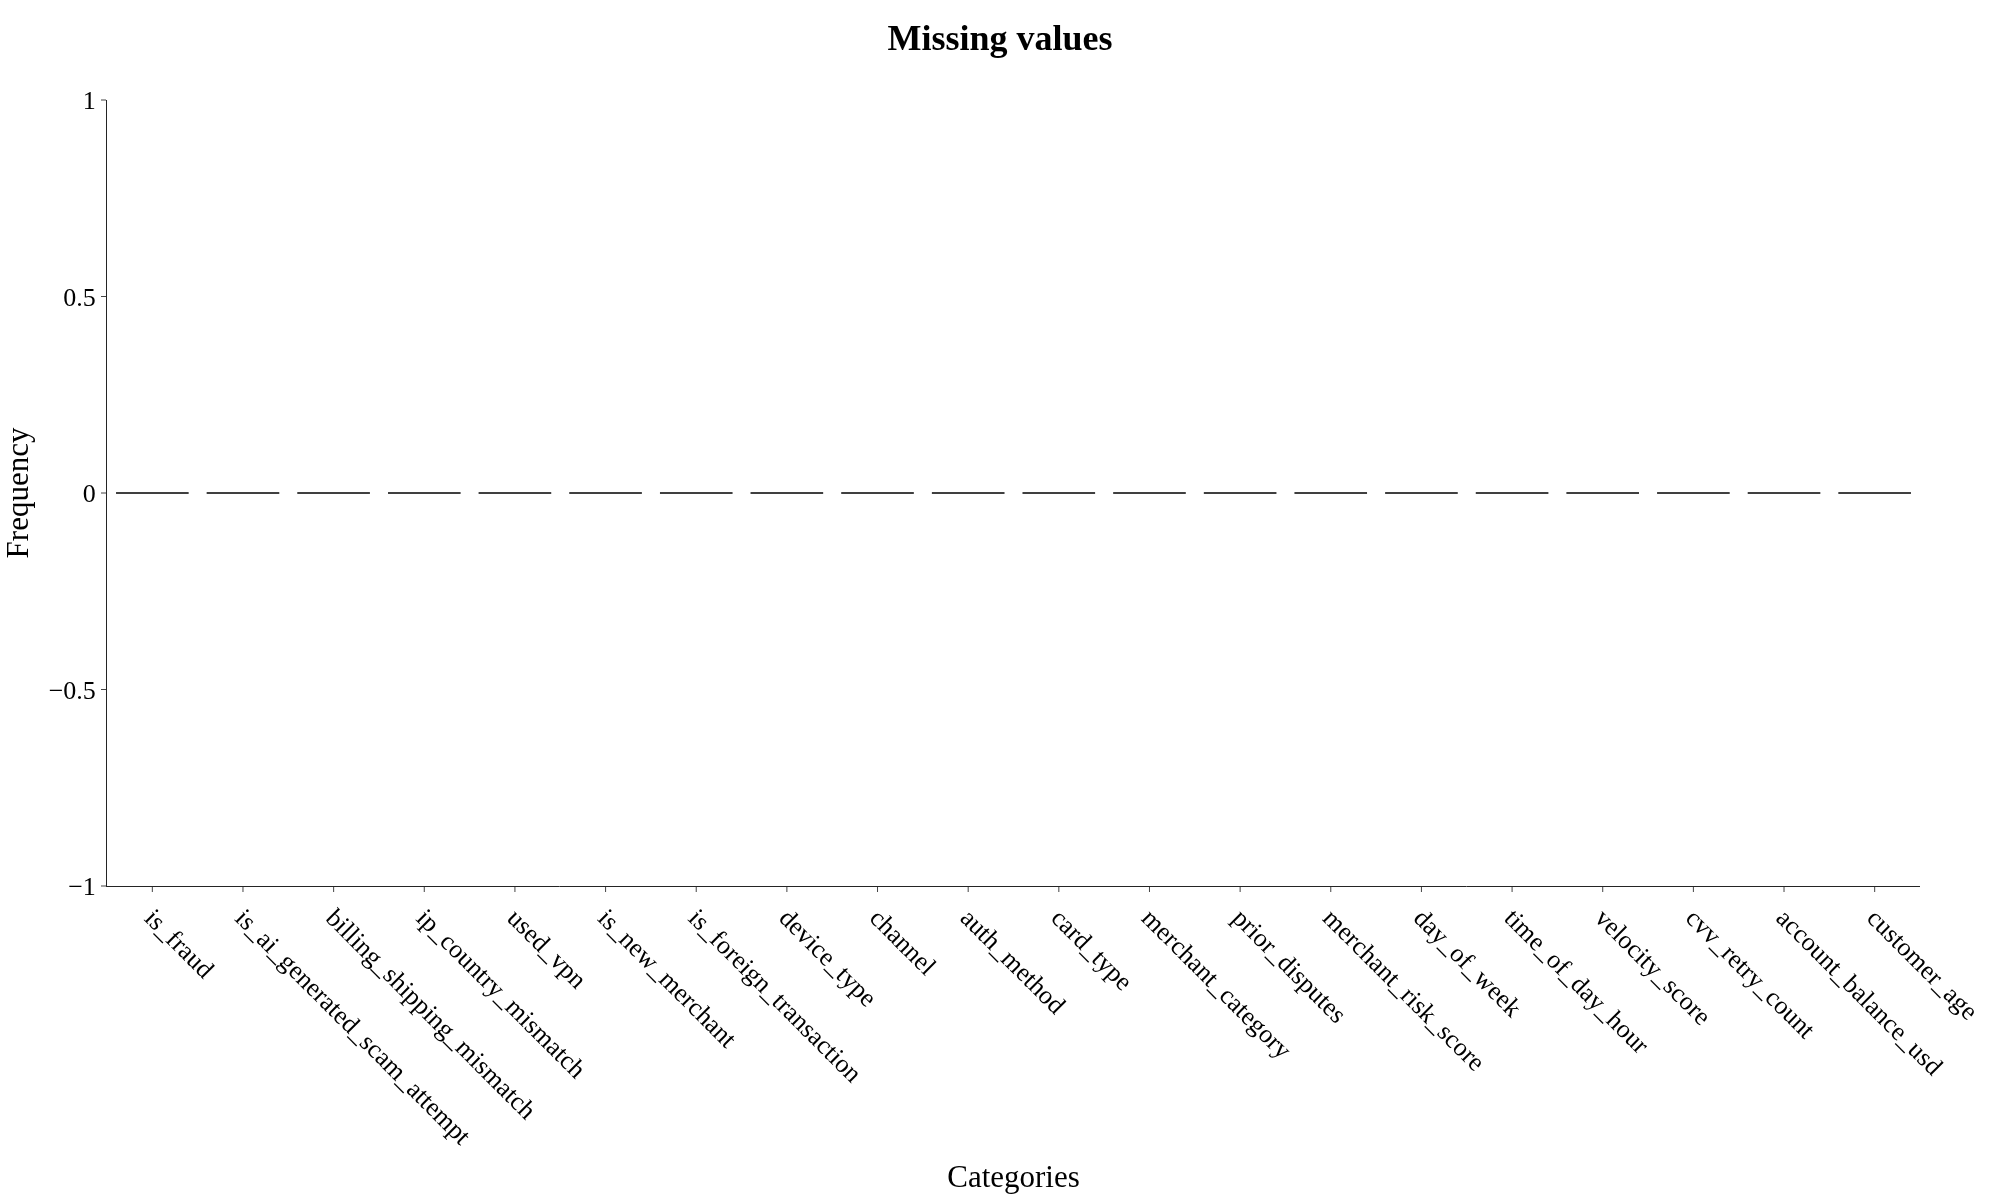

In [6]:
categorical_plots.barplot(train_data.isna().sum(), plot_title="Missing values", top_n=20, show_other=False, tickangle=45, width=2000, height=1200)

# Features exploration

In [7]:
train_data.columns = [ feature.upper().replace(" ", "_") for feature in train_data.columns ]
test_data.columns = [feature.upper().replace(" ", "_") for feature in test_data.columns]
features = train_data.columns.tolist()
features = [ (feature.upper().replace(" ", "_"), train_data[feature].dtype) for feature in features ]
TARGET_FEATURE = TARGET_FEATURE.upper().replace(" ", "_")
data = train_data
for feature, dtype in features:
    print(f"- {feature} ({dtype})")

- AMOUNT_USD (float64)
- HOURS_SINCE_LAST_TXN (float64)
- TXN_COUNT_LAST_24H (int64)
- DISTANCE_FROM_HOME_KM (float64)
- CARD_AGE_MONTHS (int64)
- CUSTOMER_AGE (int64)
- ACCOUNT_BALANCE_USD (float64)
- CVV_RETRY_COUNT (int64)
- VELOCITY_SCORE (float64)
- TIME_OF_DAY_HOUR (int64)
- DAY_OF_WEEK (int64)
- MERCHANT_RISK_SCORE (float64)
- PRIOR_DISPUTES (int64)
- MERCHANT_CATEGORY (str)
- CARD_TYPE (str)
- AUTH_METHOD (str)
- CHANNEL (str)
- DEVICE_TYPE (str)
- IS_FOREIGN_TRANSACTION (int64)
- IS_NEW_MERCHANT (int64)
- USED_VPN (int64)
- IP_COUNTRY_MISMATCH (int64)
- BILLING_SHIPPING_MISMATCH (int64)
- IS_AI_GENERATED_SCAM_ATTEMPT (int64)
- IS_FRAUD (float64)


## Features Documentation


- `AMOUNT_USD` (float64): The transaction amount, in US dollars.
- `HOURS_SINCE_LAST_TXN` (float64): The number of hours elapsed since the cardholder's previous transaction.
- `TXN_COUNT_LAST_24H` (int64): The number of transactions made with the card during the preceding 24 hours.
- `DISTANCE_FROM_HOME_KM` (float64): The distance, in kilometres, between the transaction location and the cardholder's home.
- `CARD_AGE_MONTHS` (int64): The age of the card, in months, at the time of the transaction.
- `CUSTOMER_AGE` (int64): The age of the customer, in years.
- `ACCOUNT_BALANCE_USD` (float64): The account balance, in US dollars.
- `CVV_RETRY_COUNT` (int64): The number of failed CVV entry attempts before the transaction.
- `VELOCITY_SCORE` (float64): A score measuring how rapidly the card is being used, where higher values indicate faster activity.
- `TIME_OF_DAY_HOUR` (int64): The hour of the day (0-23) at which the transaction took place.
- `DAY_OF_WEEK` (int64): The day of the week (0-6) on which the transaction took place.
- `MERCHANT_RISK_SCORE` (float64): A risk score assigned to the merchant, where higher values indicate a riskier merchant.
- `PRIOR_DISPUTES` (int64): The number of disputes the customer has filed previously.
- `MERCHANT_CATEGORY` (str): The category of the merchant (e.g. Groceries, Gaming, Crypto Exchange, Gift Cards).
- `CARD_TYPE` (str): The card network (Visa, Mastercard, Amex, RuPay or Discover).
- `AUTH_METHOD` (str): The method used to authenticate the transaction (e.g. PIN, OTP, Biometric, 3D Secure, No Authentication).
- `CHANNEL` (str): The channel through which the transaction was made (Online, POS, Contactless, In-App or ATM).
- `DEVICE_TYPE` (str): The type of device used for the transaction (e.g. Android Phone, iPhone, POS Terminal, Windows PC).
- `IS_FOREIGN_TRANSACTION` (int64): Binary flag indicating whether the transaction was made abroad.
- `IS_NEW_MERCHANT` (int64): Binary flag indicating whether the cardholder is transacting with this merchant for the first time.
- `USED_VPN` (int64): Binary flag indicating whether a VPN was used for the transaction.
- `IP_COUNTRY_MISMATCH` (int64): Binary flag indicating whether the IP address country differs from the card's country.
- `BILLING_SHIPPING_MISMATCH` (int64): Binary flag indicating whether the billing and shipping addresses differ.
- `IS_AI_GENERATED_SCAM_ATTEMPT` (int64): Binary flag indicating whether the transaction was flagged as an AI-generated scam attempt.
- `IS_FRAUD` (float64): Target variable indicating whether the transaction was fraudulent (1) or legitimate (0).

# Feature Visualization

## Individual Feature Analysis

## `IS_FRAUD`

`IS_FRAUD` (float64) - Target variable indicating whether the transaction was fraudulent (1) or legitimate (0).

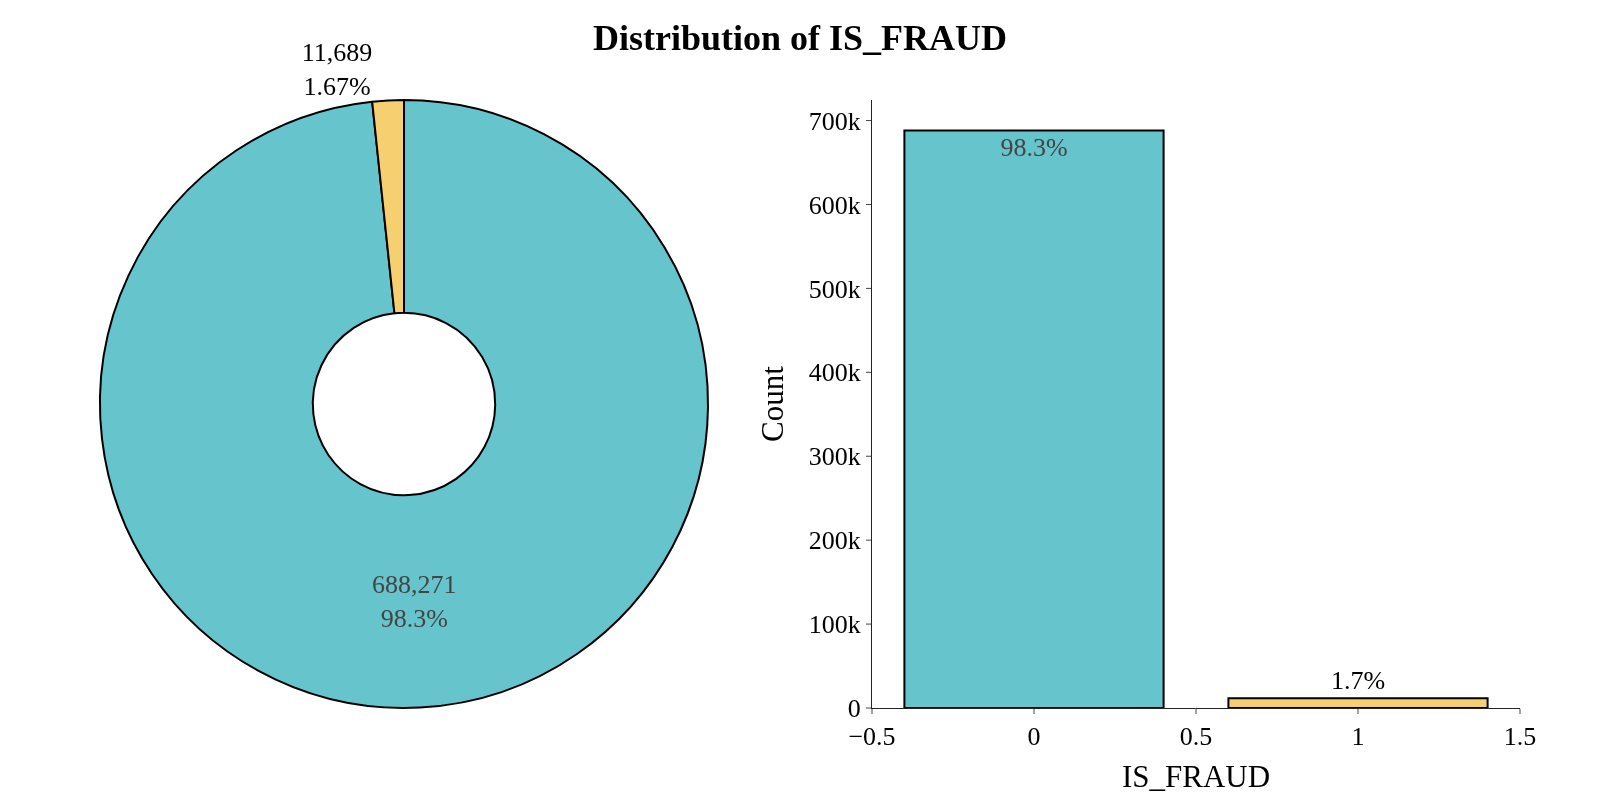

,Category,Count,Percentage (%)
0,0.000000,"688,271",98.33%
1,1.000000,"11,689",1.67%


In [8]:
feature = "IS_FRAUD"
categorical_plots.pie_barplot(data, feature, plot_title=f"Distribution of {feature}")
data_analyzer.describe_categorical_feature(data, feature)

**Notes:**
- Strongly imbalanced binary target: 11,689 fraudulent rows (1.67%) vs 688,271 legitimate (98.33%), a ratio of about 59:1; no missing values.
- Stored as float64 (0.0/1.0) although it is a pure binary label.

**Conclusion:**
- With a ~1.7% positive rate, stratified CV folds keep enough positives per fold, and ranking metrics (ROC AUC / PR AUC) are more informative than accuracy; tree-based models usually do better by tuning class weights or thresholds than by resampling.

## `AMOUNT_USD`

`AMOUNT_USD` (float64) - The transaction amount, in US dollars.

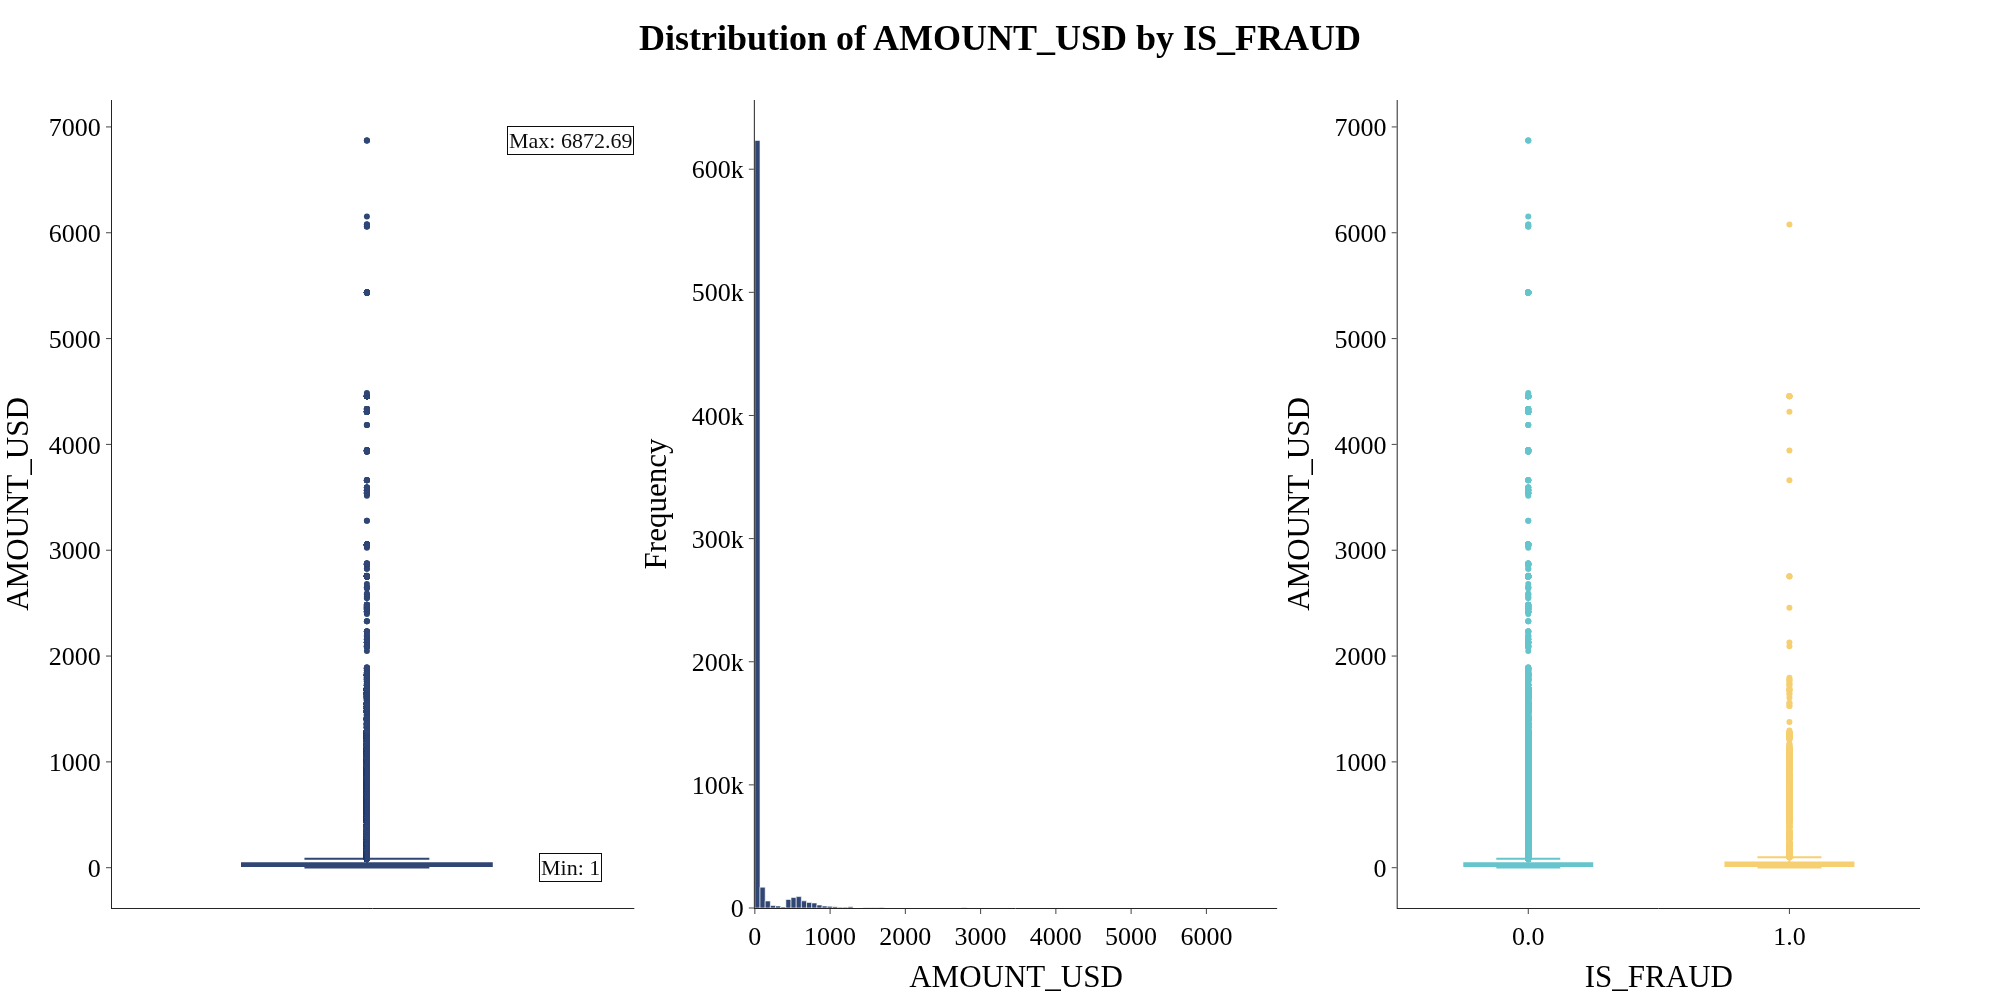

,Count,Mean,Std,Min,5%,Q1,Median,Q3,95%,Max,variance,skewness,kurtosis,Missing,Missing (%)
AMOUNT_USD,"699,960",79.89,205.17,1.00,6.86,15.81,27.25,43.11,542.46,"6,872.69","42,096.18",7.00,97.27,0,0.00%


In [9]:
feature = "AMOUNT_USD"
continuous_plots.boxplot_histogram_boxplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_numerical_feature(data, feature)

**Notes:**
- Extremely right-skewed (skewness ≈ 7.00, kurtosis ≈ 97.27) from 1.00 to 6,872.69, median 27.25; 70,741 rows (10.11%) lie above the IQR upper bound of 84.06 and no values are missing.
- Fraud has a higher mean amount (110.51 vs 79.37), but the relationship is not monotonic: fraud rate is 1.57%, 1.47%, 1.33%, 1.53% across the four lowest quintiles and jumps to 2.45% in the top quintile (2.43% in the top 1%).

**Conclusion:**
- The signal is concentrated in the high-amount tail, and the size of a purchase relative to the account balance is likely more informative than either value alone; a ratio such as `AMOUNT_USD / ACCOUNT_BALANCE_USD` would let tree-based models capture this in one split instead of approximating it with many.

## `HOURS_SINCE_LAST_TXN`

`HOURS_SINCE_LAST_TXN` (float64) - The number of hours elapsed since the cardholder's previous transaction.

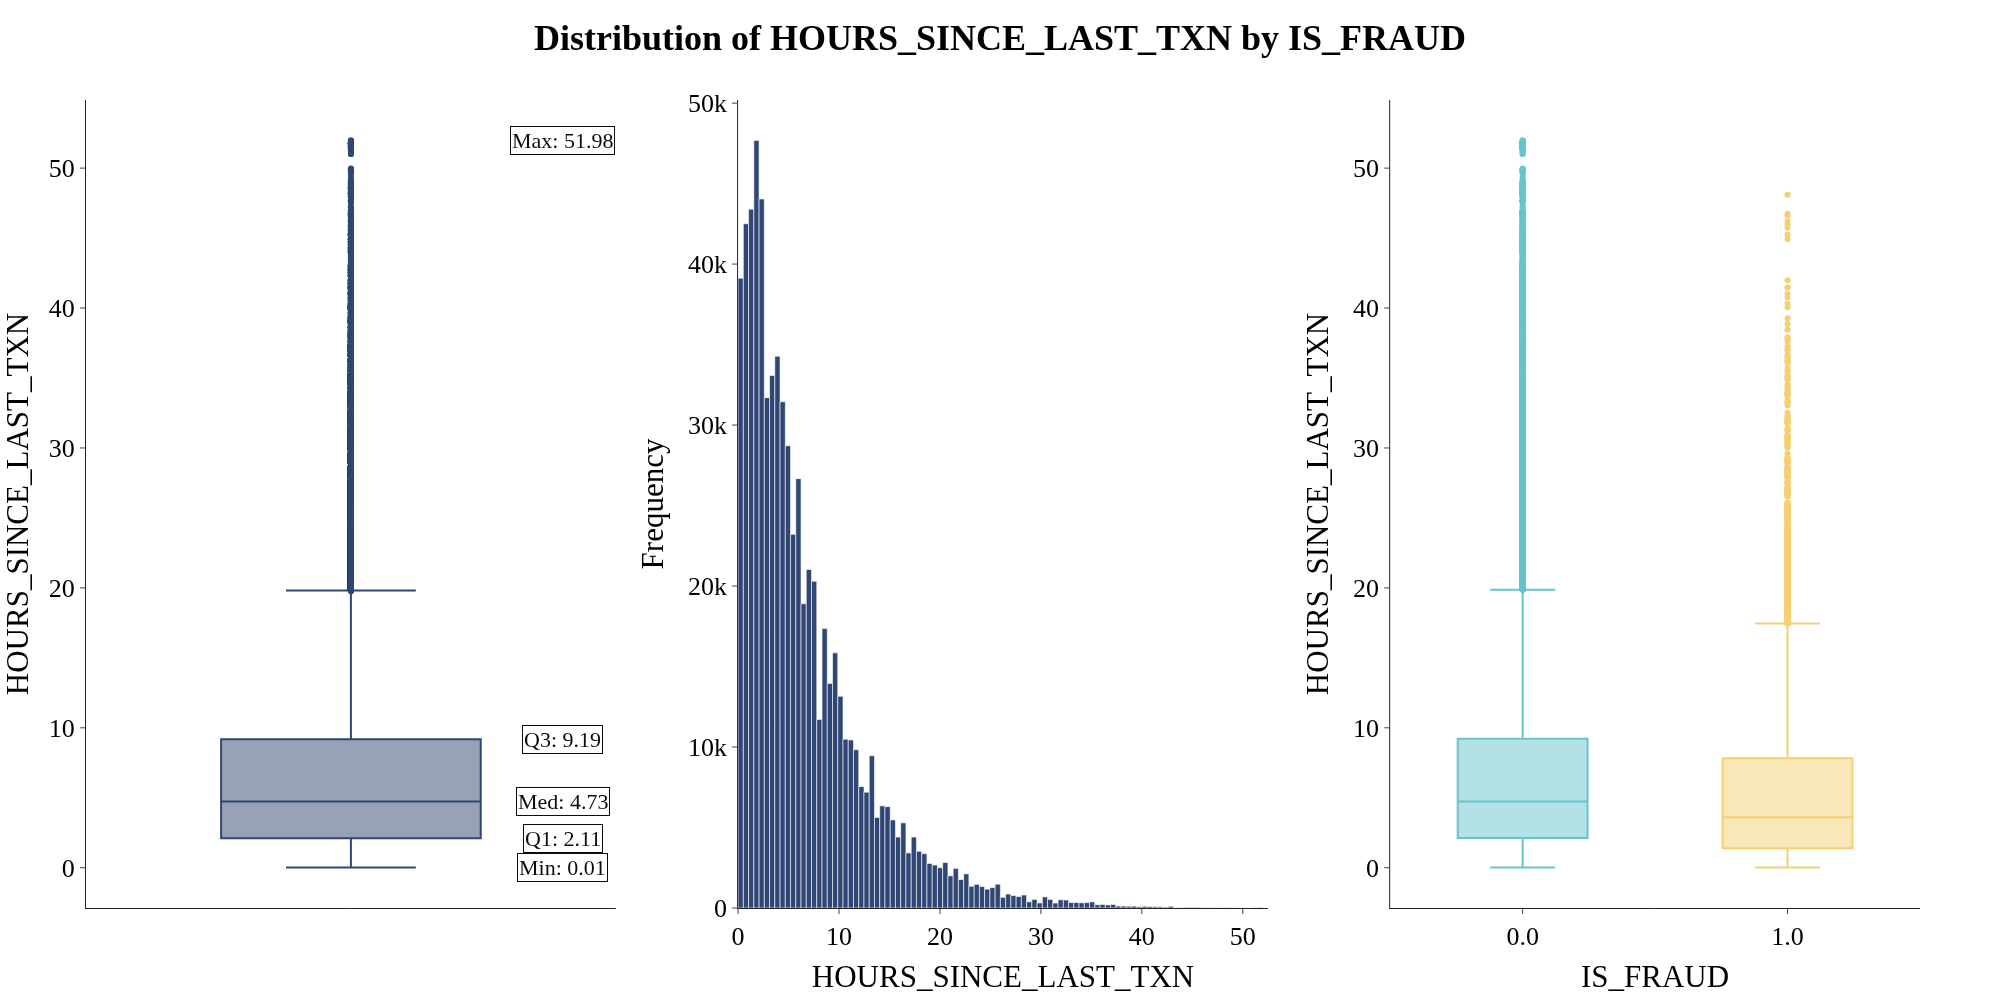

,Count,Mean,Std,Min,5%,Q1,Median,Q3,95%,Max,variance,skewness,kurtosis,Missing,Missing (%)
HOURS_SINCE_LAST_TXN,"699,960",6.63,6.29,0.01,0.47,2.11,4.73,9.19,19.40,51.98,39.57,1.82,4.40,0,0.00%


In [10]:
feature = "HOURS_SINCE_LAST_TXN"
continuous_plots.boxplot_histogram_boxplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_numerical_feature(data, feature)

**Notes:**
- Right-skewed (skewness ≈ 1.82, kurtosis ≈ 4.40) from 0.01 to 51.98 hours, median 4.73, no missing values; 32,816 rows (4.69%) exceed the IQR upper bound of 19.81 and they have a 1.40% fraud rate, close to the base rate.
- Fraud occurs after shorter gaps (mean 5.65 vs 6.65 hours); the fraud rate falls from 2.50% in the shortest-gap quintile to 1.36-1.37% in the two longest, and reaches 4.53% for the bottom 1% of gaps.

**Conclusion:**
- Very short gaps carry the signal and `TXN_COUNT_LAST_24H` captures the same burst behaviour, so a combined activity-rate feature (e.g. transactions per hour) could expose the interaction directly to tree-based models.

## `TXN_COUNT_LAST_24H`

`TXN_COUNT_LAST_24H` (int64) - The number of transactions made with the card during the preceding 24 hours.

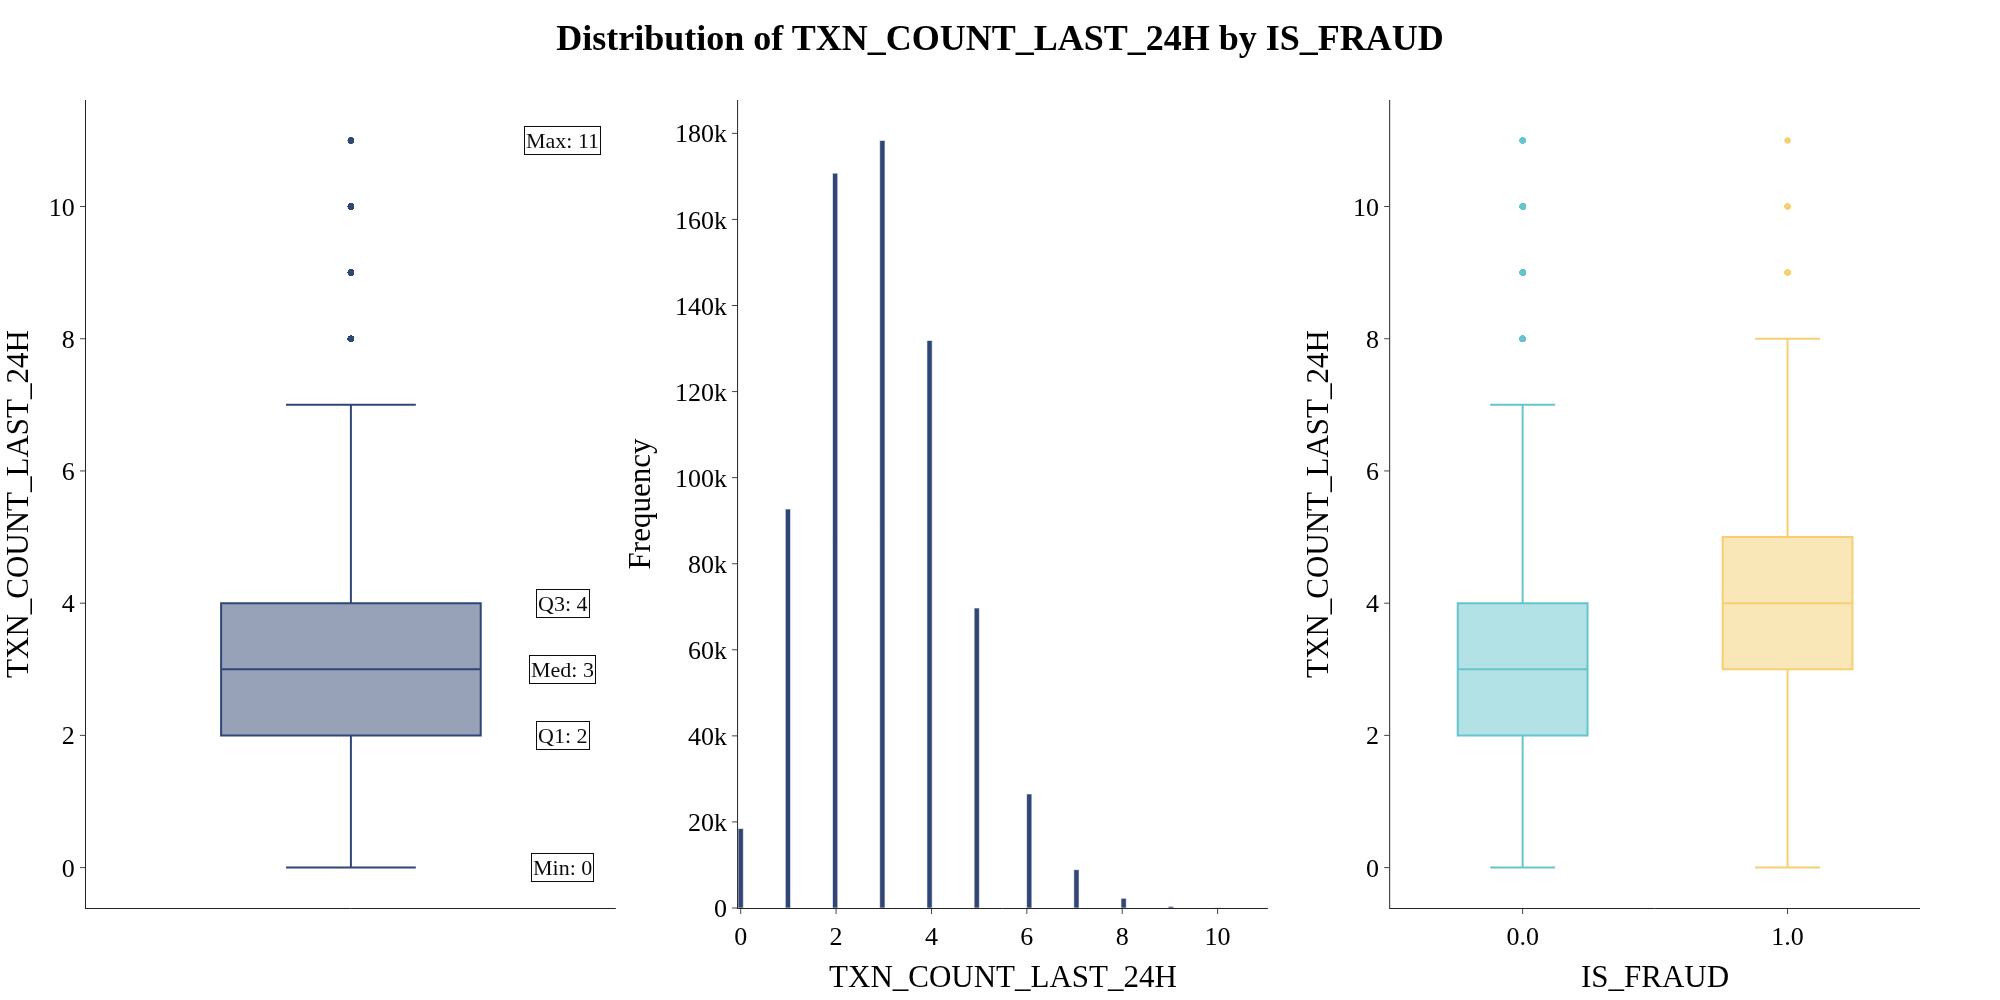

,Count,Mean,Std,Min,5%,Q1,Median,Q3,95%,Max,variance,skewness,kurtosis,Missing,Missing (%)
TXN_COUNT_LAST_24H,"699,960",2.98,1.50,0.00,1.00,2.00,3.00,4.00,6.00,11.00,2.25,0.44,0.11,0,0.00%


In [11]:
feature = "TXN_COUNT_LAST_24H"
continuous_plots.boxplot_histogram_boxplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_numerical_feature(data, feature)

**Notes:**
- Discrete count from 0 to 11, nearly symmetric (skewness ≈ 0.44, kurtosis ≈ 0.11), median 3; levels 2-4 hold 68.7% of rows, no missing values, and 2,704 rows (0.39%) exceed the IQR upper bound of 7.
- Fraud rate rises almost monotonically with the count: 0.23% (0), 1.28% (2), 1.66% (3), 2.59% (5), 5.82% (9), 12.31% (10) and 22.22% (11); the mean is 3.65 for fraud vs 2.97 for legitimate.

**Conclusion:**
- Levels 9-11 together cover about 0.06% of rows, so their fraud rates rest on very few observations; capping or merging them into one top bucket (e.g. 9+) would give tree-based models a stable leaf instead of splits fitted on a handful of rows.

## `DISTANCE_FROM_HOME_KM`

`DISTANCE_FROM_HOME_KM` (float64) - The distance, in kilometres, between the transaction location and the cardholder's home.

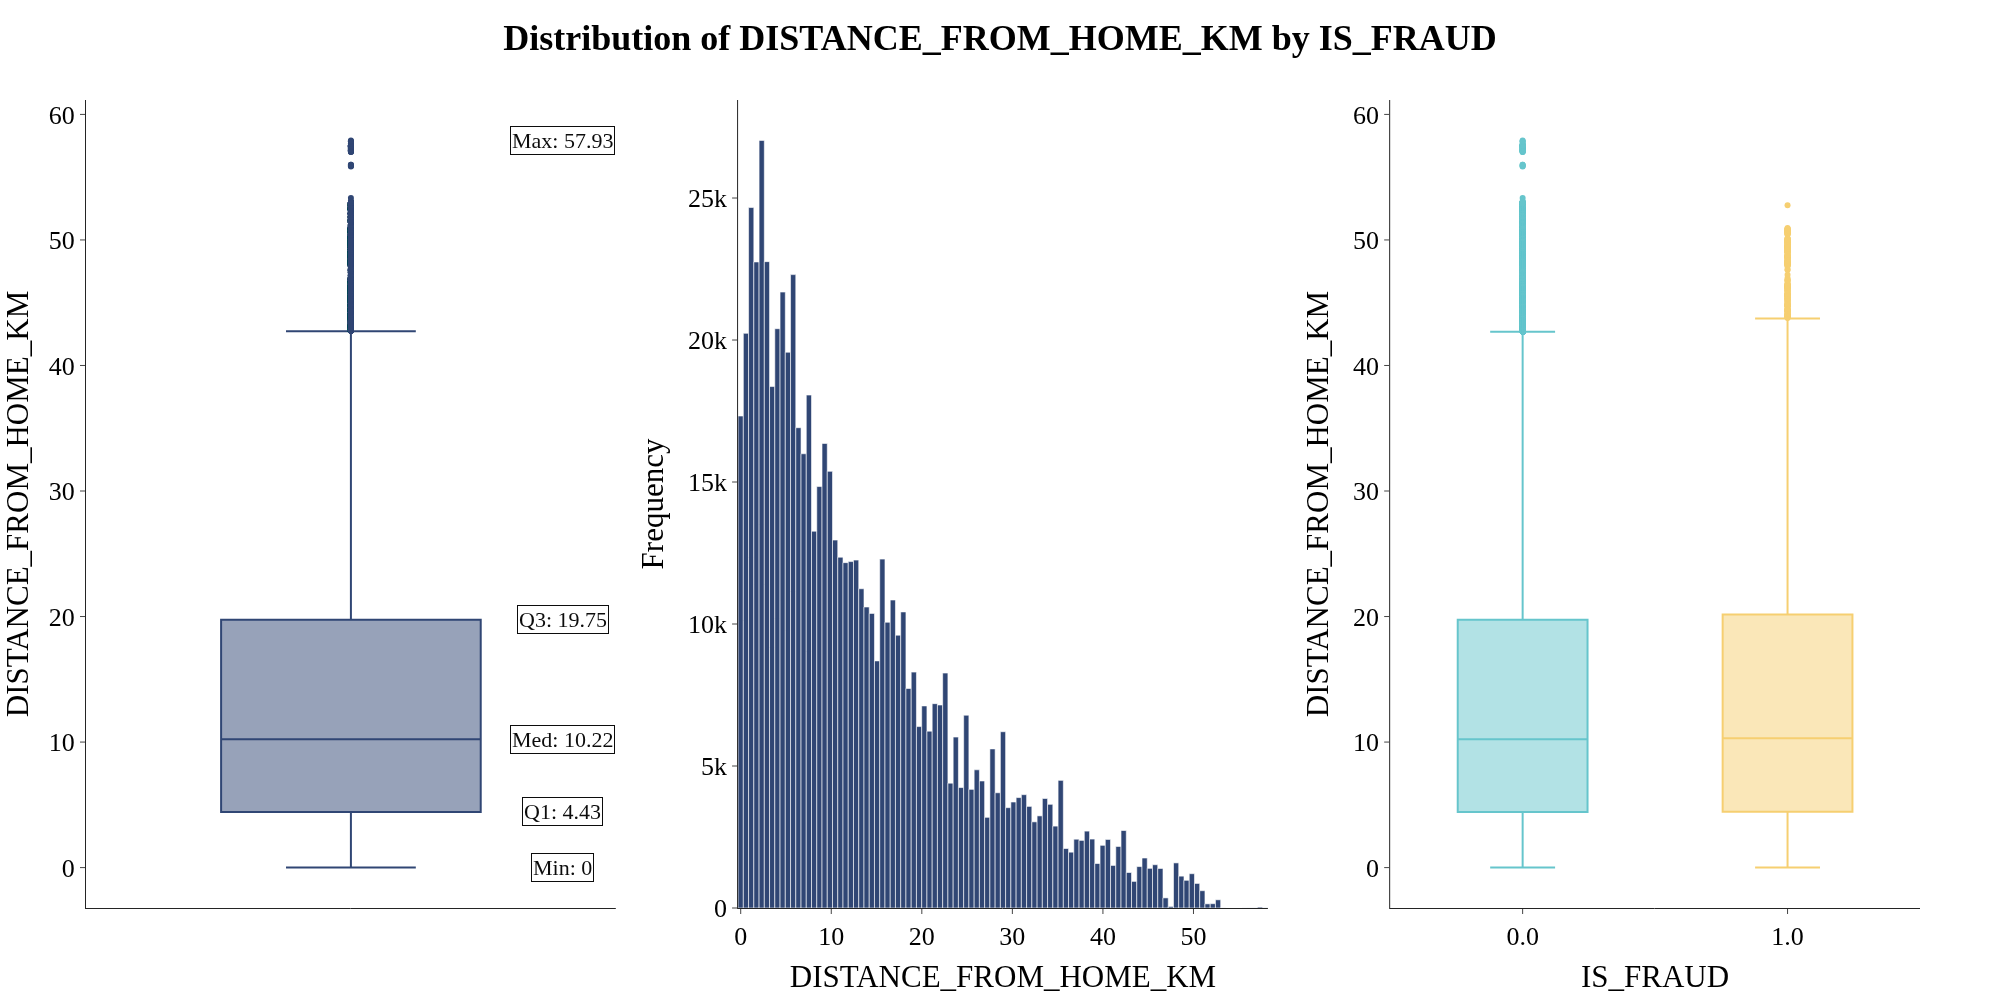

,Count,Mean,Std,Min,5%,Q1,Median,Q3,95%,Max,variance,skewness,kurtosis,Missing,Missing (%)
DISTANCE_FROM_HOME_KM,"699,960",13.59,11.62,0.00,0.76,4.43,10.22,19.75,37.94,57.93,134.96,1.06,0.45,0,0.00%


In [12]:
feature = "DISTANCE_FROM_HOME_KM"
continuous_plots.boxplot_histogram_boxplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_numerical_feature(data, feature)

**Notes:**
- Right-skewed (skewness ≈ 1.06, kurtosis ≈ 0.45) from 0.00 to 57.93 km, median 10.22, no missing values; 16,770 rows (2.40%) exceed the IQR upper bound of 42.73.
- Almost no target relationship: mean distance is 13.75 for fraud vs 13.59 for legitimate, and the fraud rate is flat at 1.62-1.70% across all five quintiles.

## `CARD_AGE_MONTHS`

`CARD_AGE_MONTHS` (int64) - The age of the card, in months, at the time of the transaction.

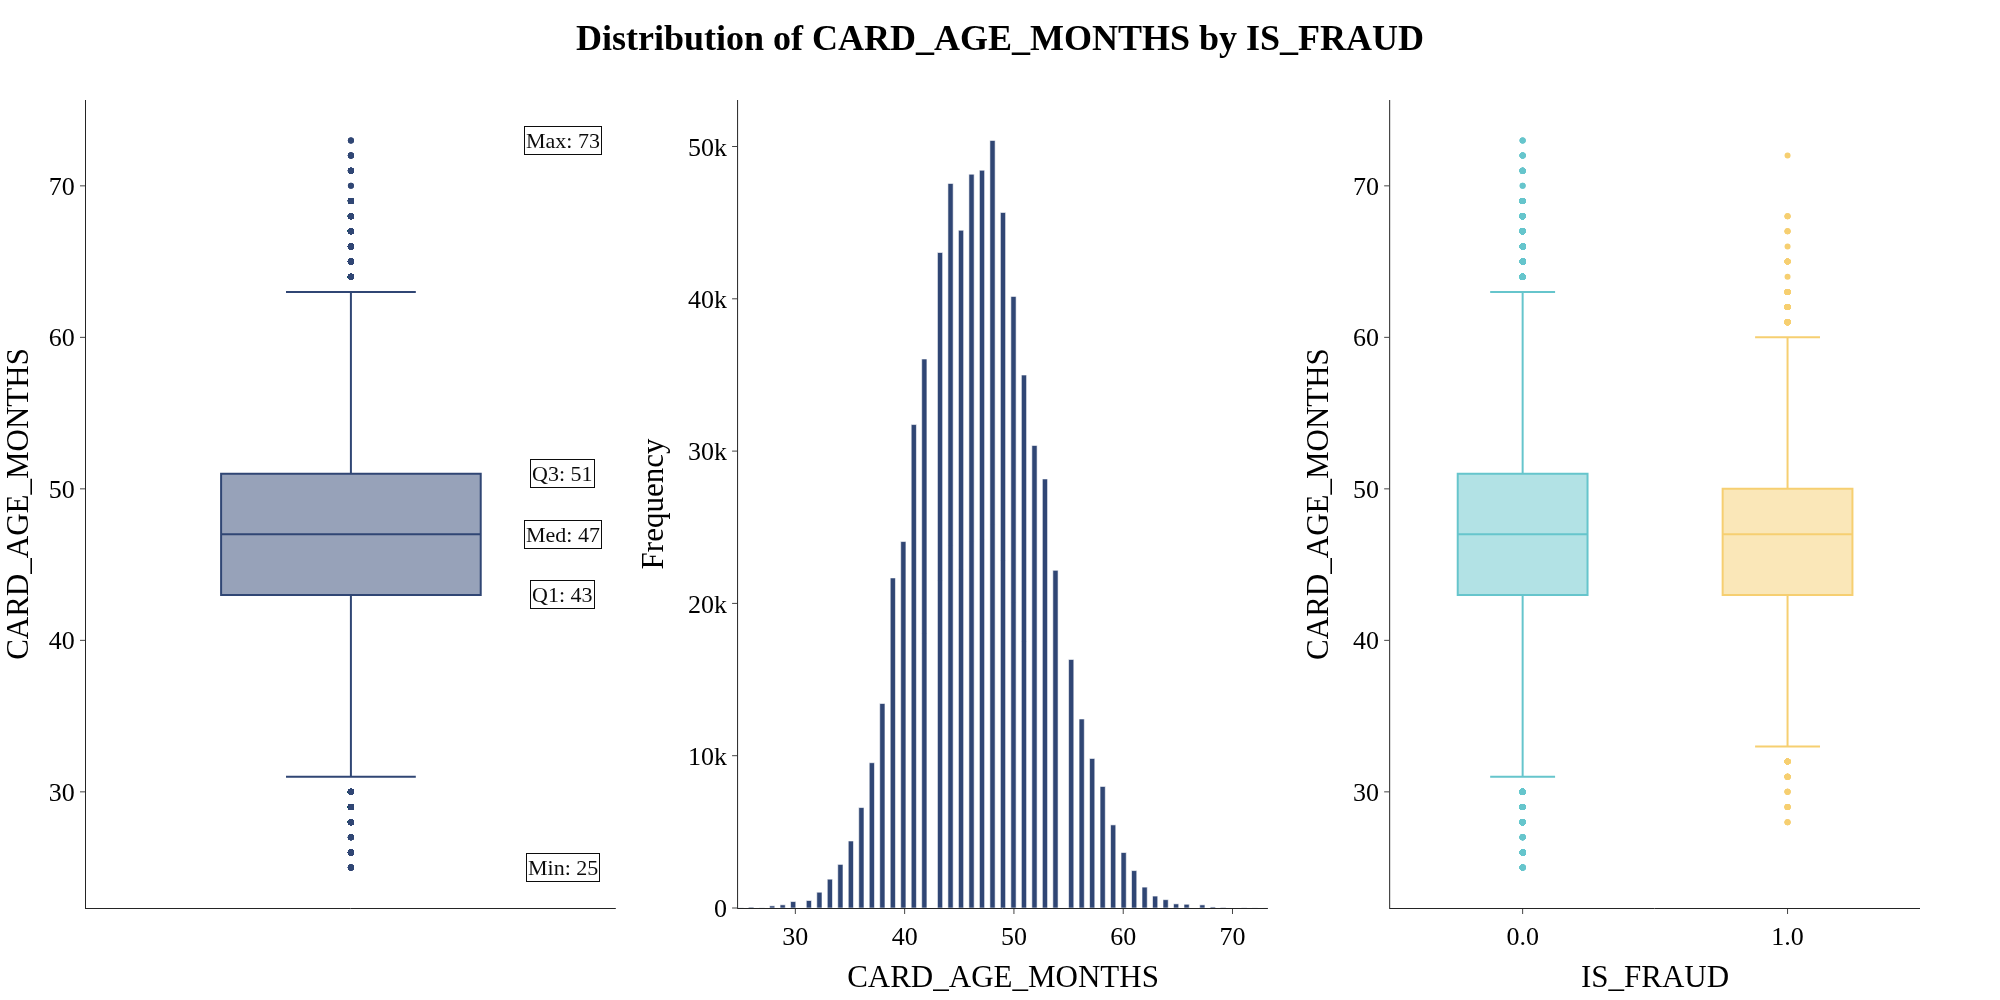

,Count,Mean,Std,Min,5%,Q1,Median,Q3,95%,Max,variance,skewness,kurtosis,Missing,Missing (%)
CARD_AGE_MONTHS,"699,960",46.86,5.58,25.00,38.00,43.00,47.00,51.00,56.00,73.00,31.13,0.13,-0.02,0,0.00%


In [13]:
feature = "CARD_AGE_MONTHS"
continuous_plots.boxplot_histogram_boxplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_numerical_feature(data, feature)

**Notes:**
- Nearly symmetric (skewness ≈ 0.13, kurtosis ≈ -0.02) from 25 to 73 months, median 47, no missing values; 2,253 rows (0.32%) fall outside the IQR bounds of 31-63.
- No target relationship: mean age is 46.89 for fraud vs 46.86 for legitimate, and the fraud rate stays within 1.63-1.70% across quintiles.

## `CUSTOMER_AGE`

`CUSTOMER_AGE` (int64) - The age of the customer, in years.

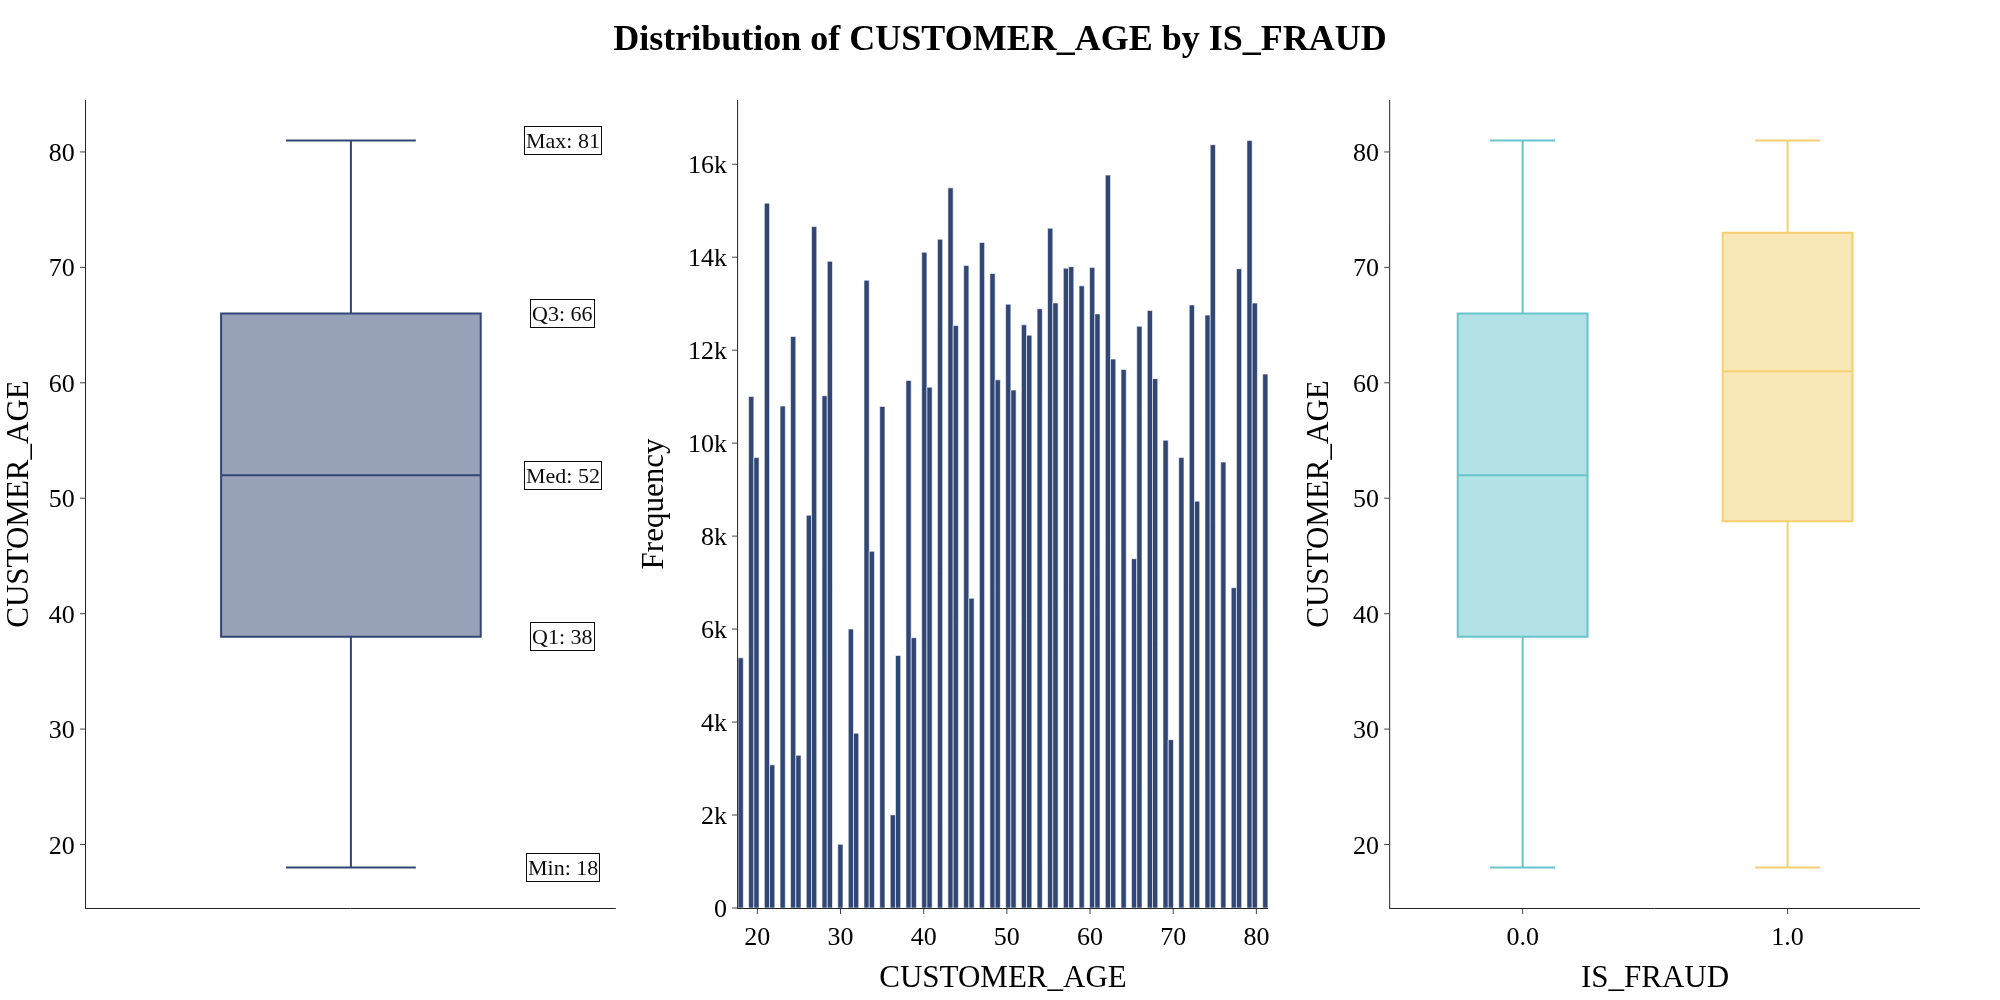

,Count,Mean,Std,Min,5%,Q1,Median,Q3,95%,Max,variance,skewness,kurtosis,Missing,Missing (%)
CUSTOMER_AGE,"699,960",51.43,17.90,18.00,21.00,38.00,52.00,66.00,79.00,81.00,320.38,-0.14,-1.05,0,0.00%


In [14]:
feature = "CUSTOMER_AGE"
continuous_plots.boxplot_histogram_boxplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_numerical_feature(data, feature)

**Notes:**
- Roughly uniform-like, flat distribution from 18 to 81 years (skewness ≈ -0.14, kurtosis ≈ -1.05), median 52, no missing values and no IQR outliers.
- Older customers are more often victims: mean age is 59.13 for fraud vs 51.30 for legitimate, and the fraud rate increases monotonically by quintile from 0.51% (18-33) to 1.48%, 1.69%, 1.93% and 2.82% (69-81).

## `ACCOUNT_BALANCE_USD`

`ACCOUNT_BALANCE_USD` (float64) - The account balance, in US dollars.

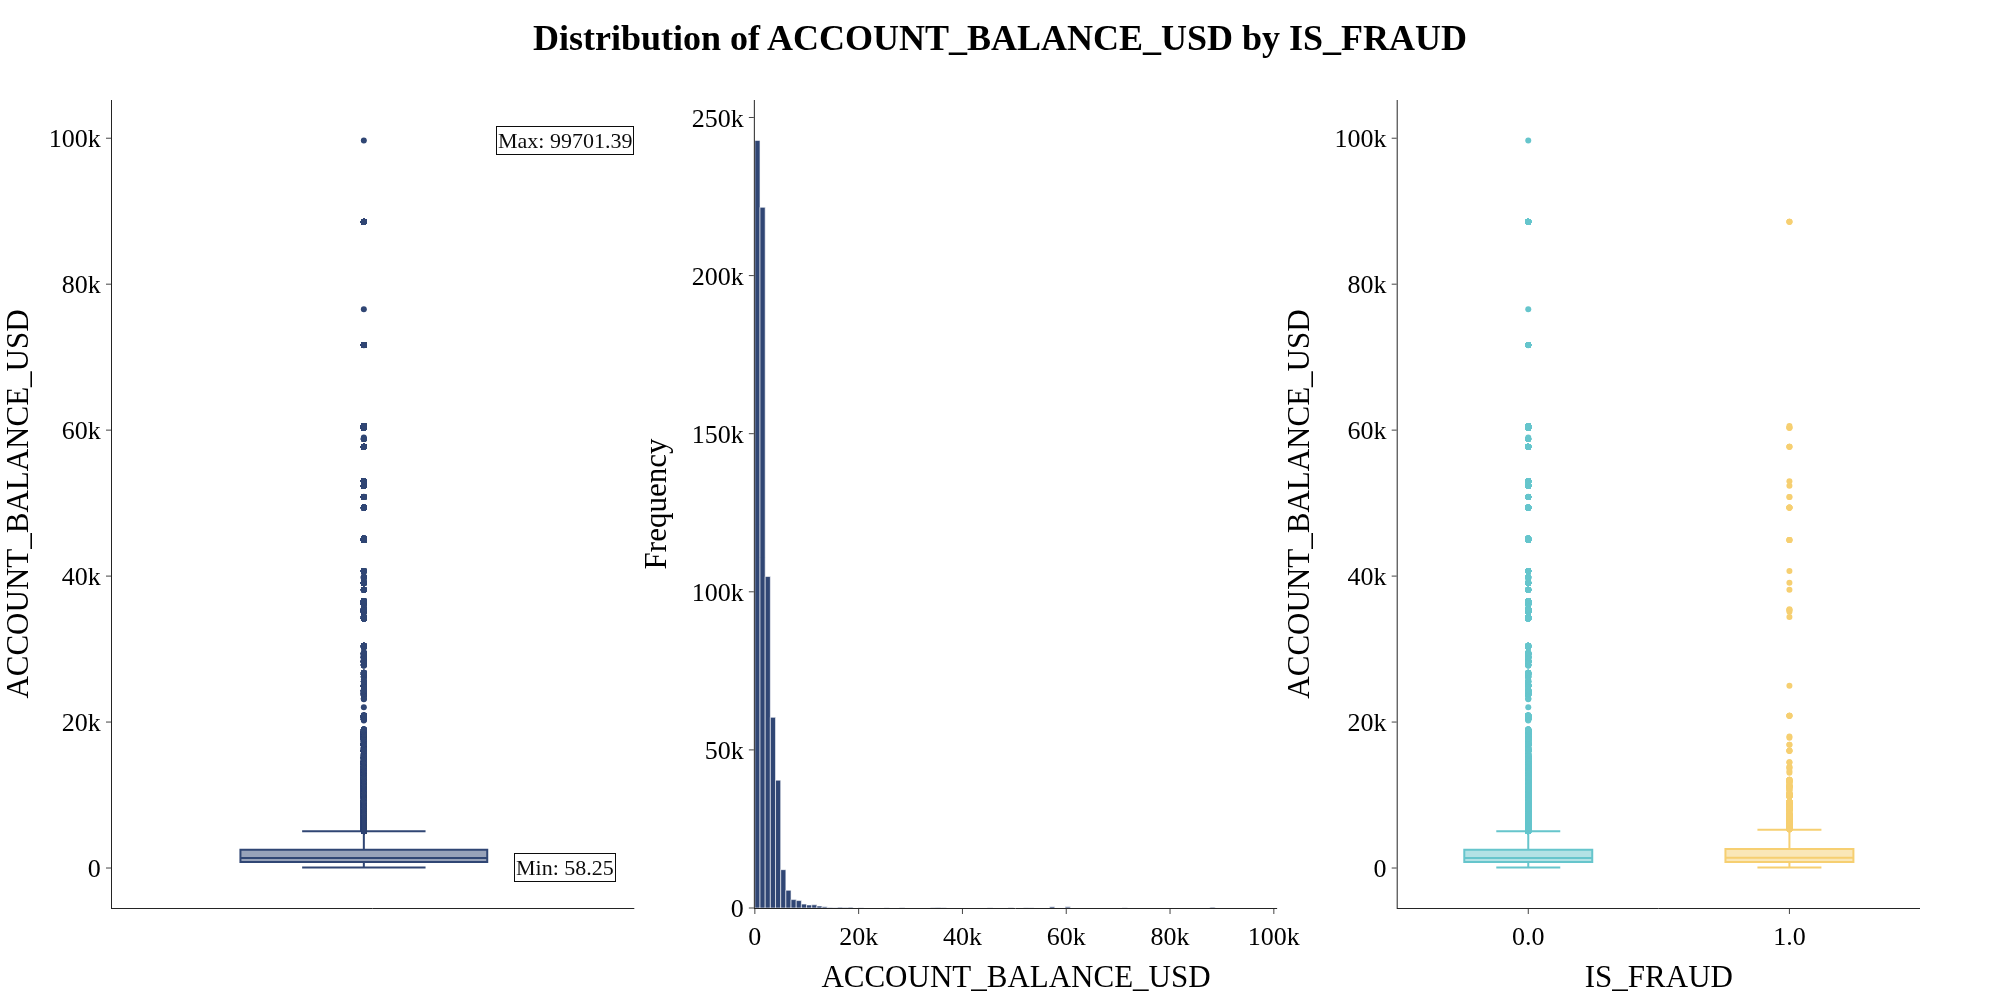

,Count,Mean,Std,Min,5%,Q1,Median,Q3,95%,Max,variance,skewness,kurtosis,Missing,Missing (%)
ACCOUNT_BALANCE_USD,"699,960","2,065.00","3,400.13",58.25,532.61,834.12,"1,382.74","2,517.02","4,861.18","99,701.39","11,560,903.88",14.44,278.35,0,0.00%


In [15]:
feature = "ACCOUNT_BALANCE_USD"
continuous_plots.boxplot_histogram_boxplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_numerical_feature(data, feature)

**Notes:**
- Extremely right-skewed (skewness ≈ 14.44, kurtosis ≈ 278.35) from 58.25 to 99,701.39, median 1,382.74, no missing values; 29,068 rows (4.15%) exceed the IQR upper bound of 5,041.37.
- Weak target relationship: mean balance is 2,093.09 for fraud vs 2,064.52 for legitimate, and the fraud rate sits at 1.58-1.82% across quintiles (1.82% in the top, 1.68% for the top 1%).

## `CVV_RETRY_COUNT`

`CVV_RETRY_COUNT` (int64) - The number of failed CVV entry attempts before the transaction.

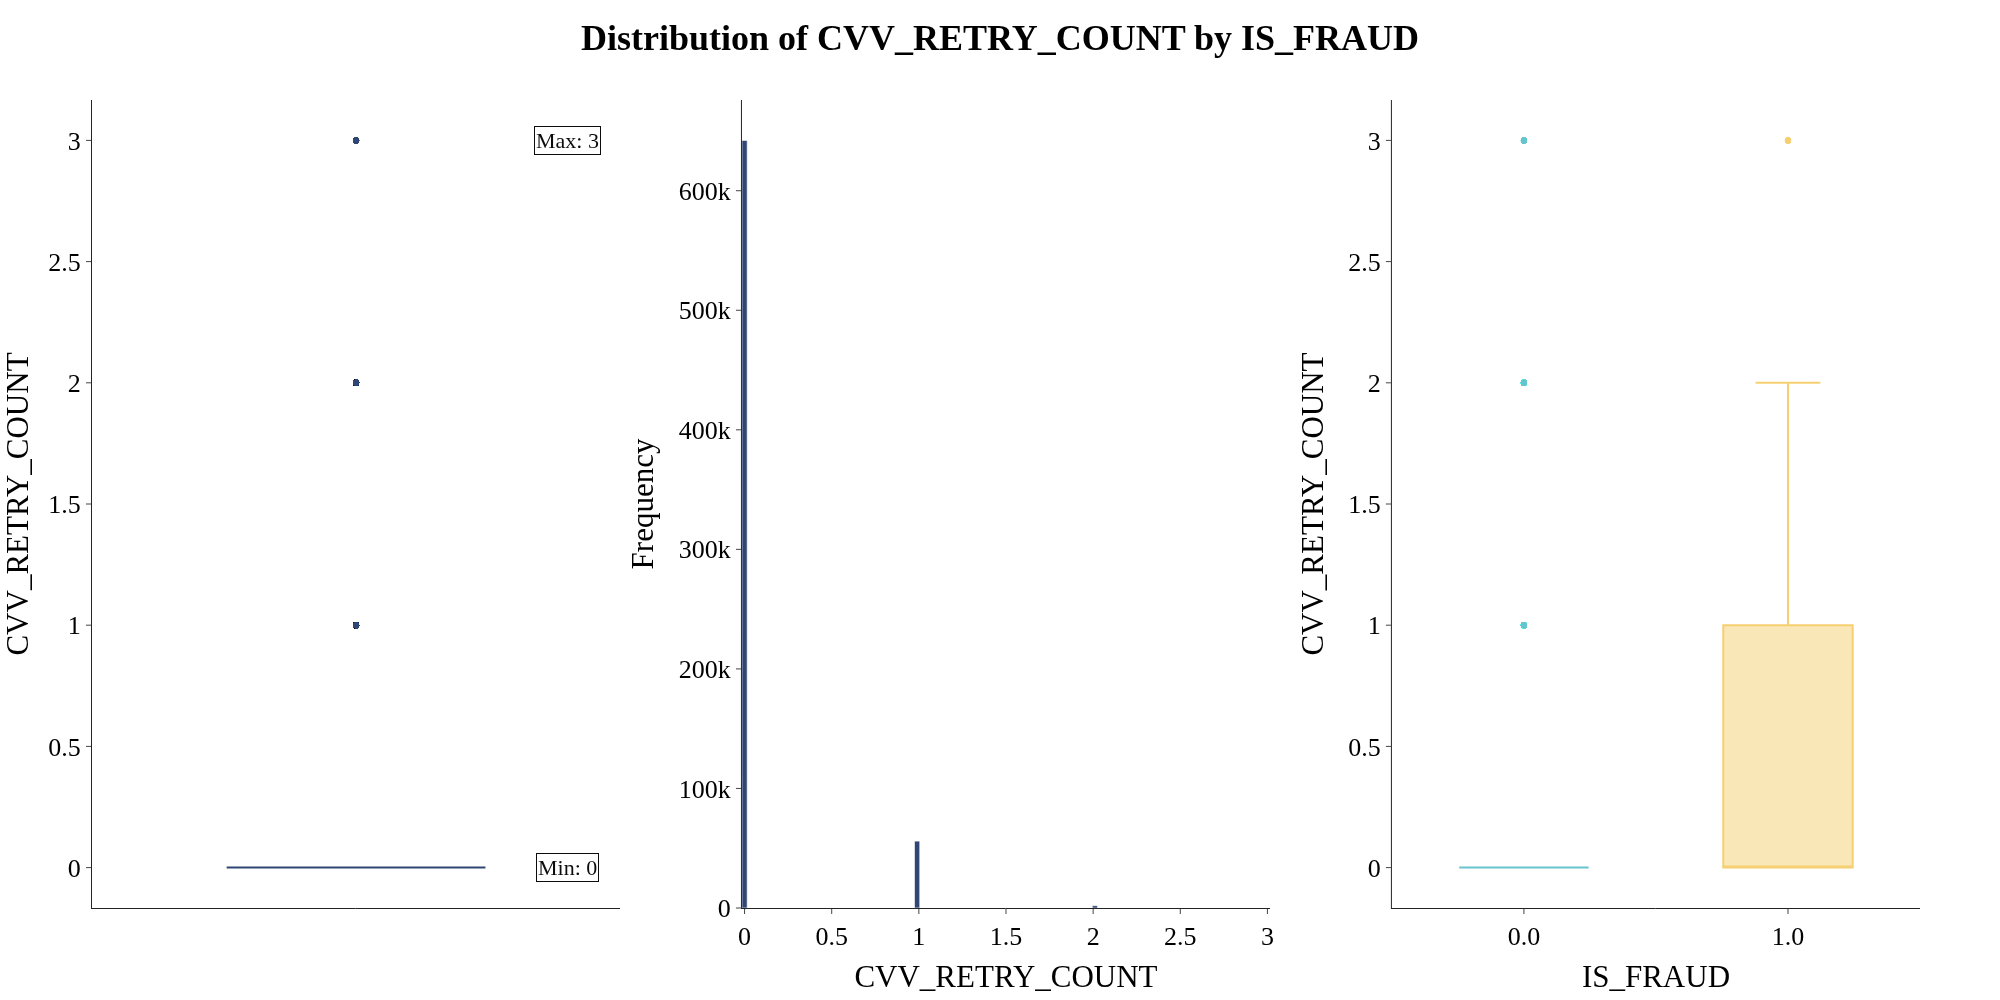

,Count,Mean,Std,Min,5%,Q1,Median,Q3,95%,Max,variance,skewness,kurtosis,Missing,Missing (%)
CVV_RETRY_COUNT,"699,960",0.09,0.29,0.00,0.00,0.00,0.00,0.00,1.00,3.00,0.08,3.32,10.53,0,0.00%


In [16]:
feature = "CVV_RETRY_COUNT"
continuous_plots.boxplot_histogram_boxplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_numerical_feature(data, feature)

**Notes:**
- Discrete count from 0 to 3, heavily right-skewed (skewness ≈ 3.32, kurtosis ≈ 10.53); 91.73% of rows have 0 retries, 7.99% have 1, 0.27% have 2 and only a handful have 3; no missing values.
- One of the strongest signals: fraud rate is 0.93% at 0 retries, 8.75% at 1, 41.73% at 2 and 36.00% at 3; mean retries are 0.557 for fraud vs 0.077 for legitimate.

**Conclusion:**
- Levels 2 and 3 are very rare and non-monotonic (41.73% vs 36.00%), so merging them into a single "2+" level, or adding a `CVV_RETRY_COUNT > 0` flag, would give tree-based models a stable split instead of noisy leaves on a few dozen rows.

## `VELOCITY_SCORE`

`VELOCITY_SCORE` (float64) - A score measuring how rapidly the card is being used, where higher values indicate faster activity.

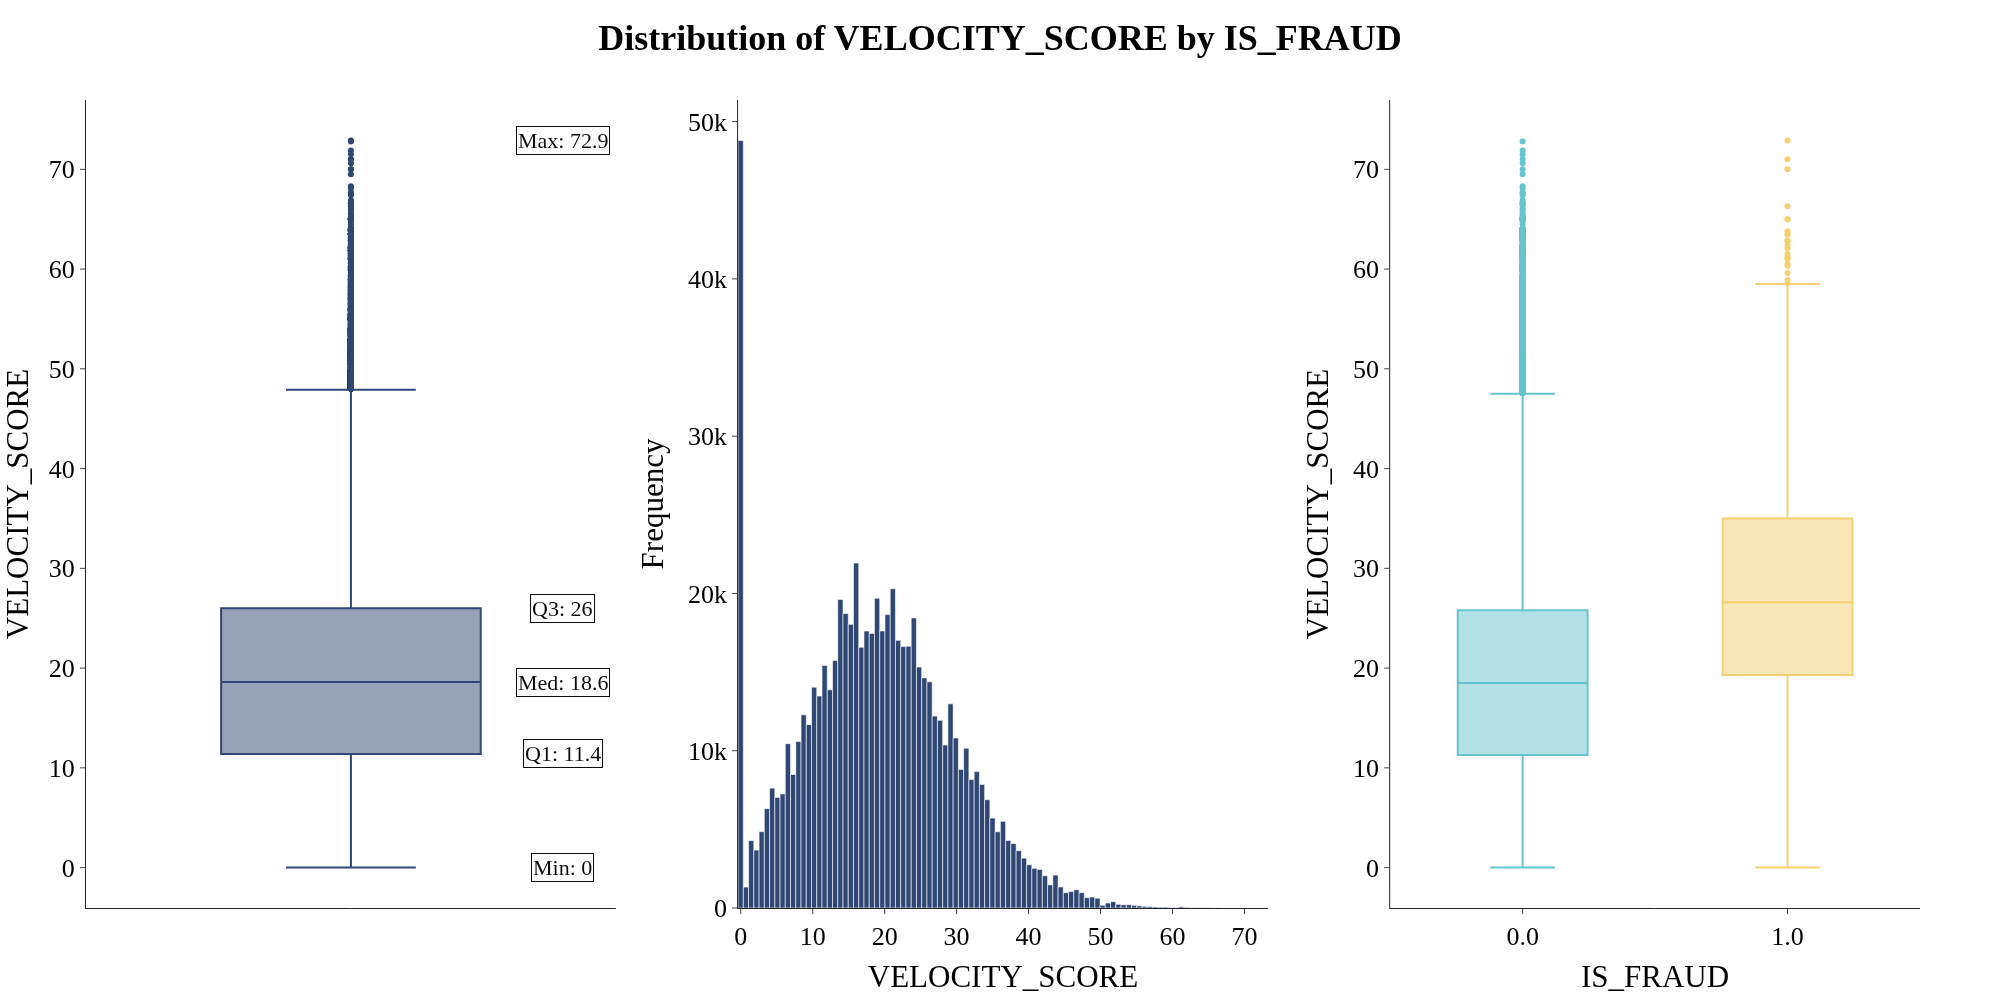

,Count,Mean,Std,Min,5%,Q1,Median,Q3,95%,Max,variance,skewness,kurtosis,Missing,Missing (%)
VELOCITY_SCORE,"699,960",18.93,10.86,0.00,0.00,11.40,18.60,26.00,37.40,72.90,118.03,0.26,-0.15,0,0.00%


In [17]:
feature = "VELOCITY_SCORE"
continuous_plots.boxplot_histogram_boxplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_numerical_feature(data, feature)

**Notes:**
- Nearly symmetric (skewness ≈ 0.26, kurtosis ≈ -0.15) from 0.00 to 72.90, median 18.60, no missing values; 4,276 rows (0.61%) exceed the IQR upper bound of 47.90 and they have a 9.26% fraud rate.
- Strong monotonic relationship: fraud rate climbs from 0.34% in the lowest quintile to 0.84%, 1.43%, 1.98% and 3.77% in the highest (8.69% for the top 1%); mean score is 27.40 for fraud vs 18.79 for legitimate.

## `TIME_OF_DAY_HOUR`

`TIME_OF_DAY_HOUR` (int64) - The hour of the day (0-23) at which the transaction took place.

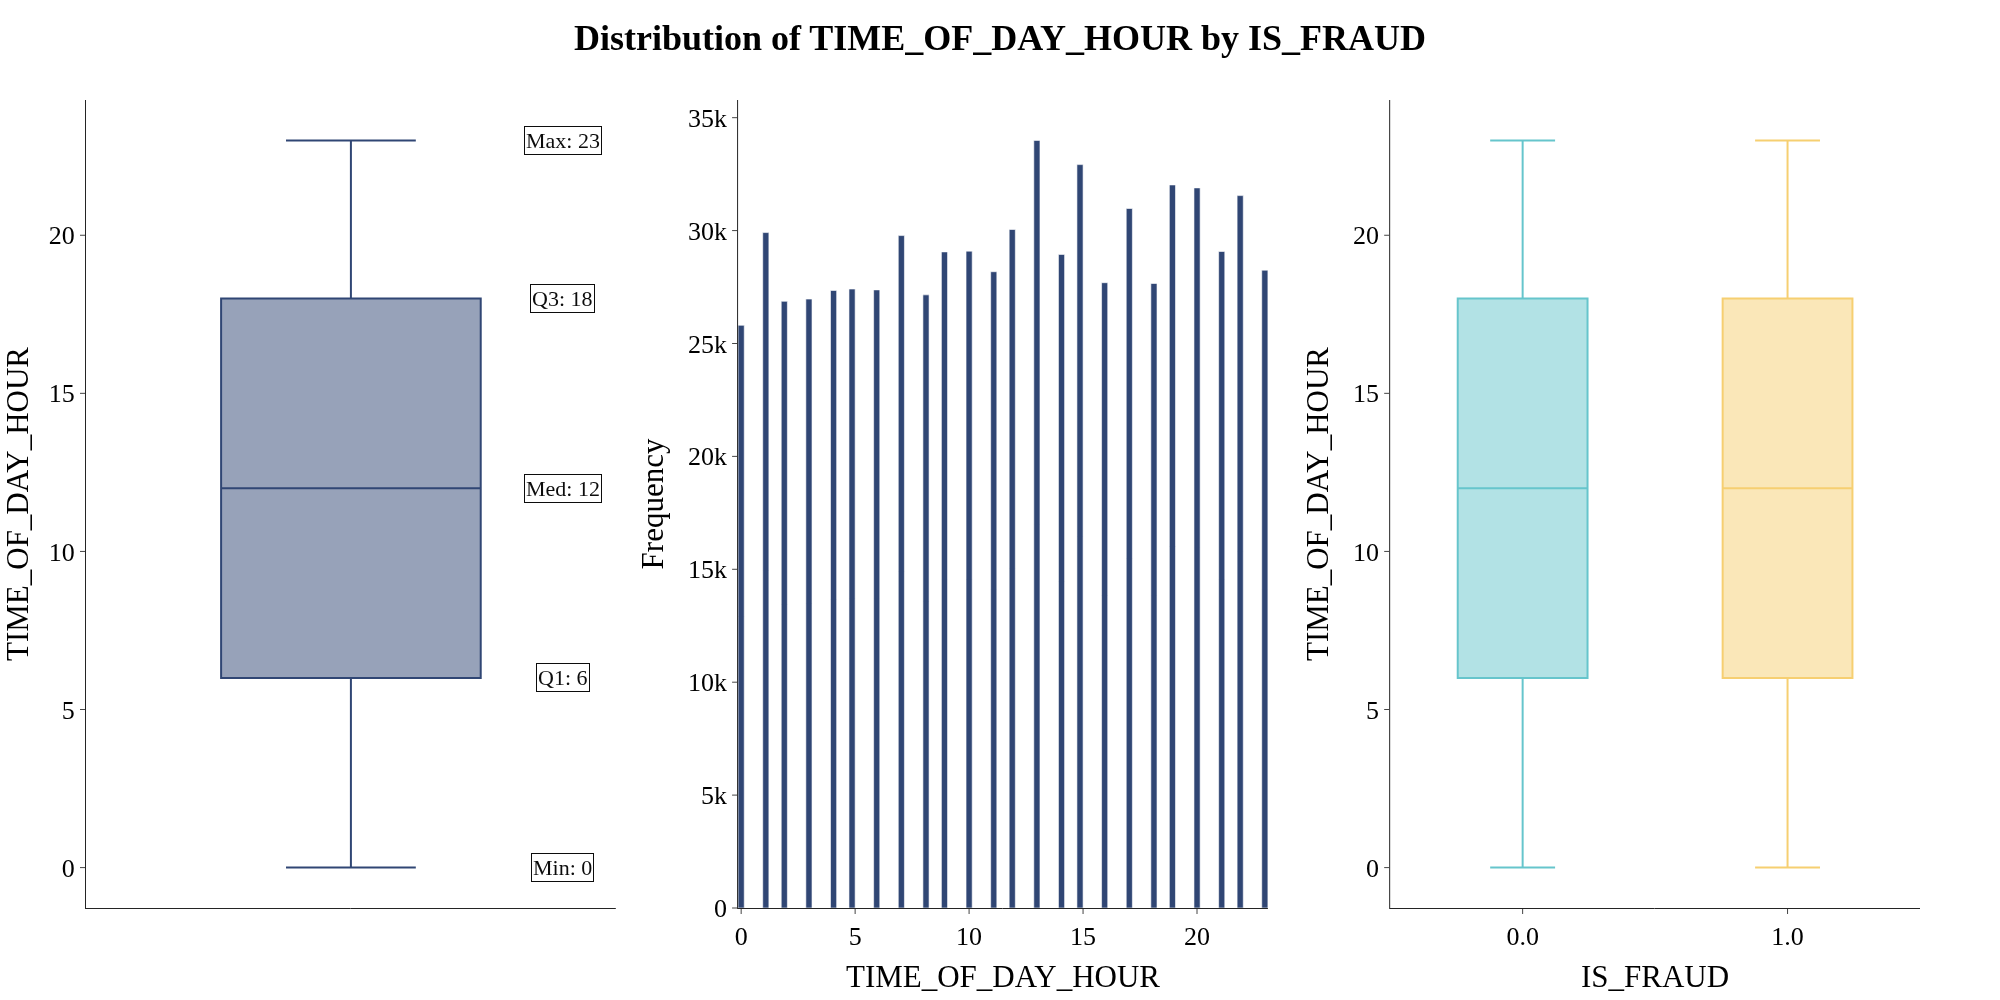

,Count,Mean,Std,Min,5%,Q1,Median,Q3,95%,Max,variance,skewness,kurtosis,Missing,Missing (%)
TIME_OF_DAY_HOUR,"699,960",11.76,6.87,0.00,1.00,6.00,12.00,18.00,22.00,23.00,47.19,-0.06,-1.18,0,0.00%


In [18]:
feature = "TIME_OF_DAY_HOUR"
continuous_plots.boxplot_histogram_boxplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_numerical_feature(data, feature)

**Notes:**
- Close to uniform across the 24 hours (skewness ≈ -0.06, kurtosis ≈ -1.18), each hour holding 3.7-4.9% of rows, no missing values or outliers.
- No target relationship: the fraud rate stays between 1.44% and 1.83% for every hour, with no night-time or daytime peak.

## `DAY_OF_WEEK`

`DAY_OF_WEEK` (int64) - The day of the week (0-6) on which the transaction took place.

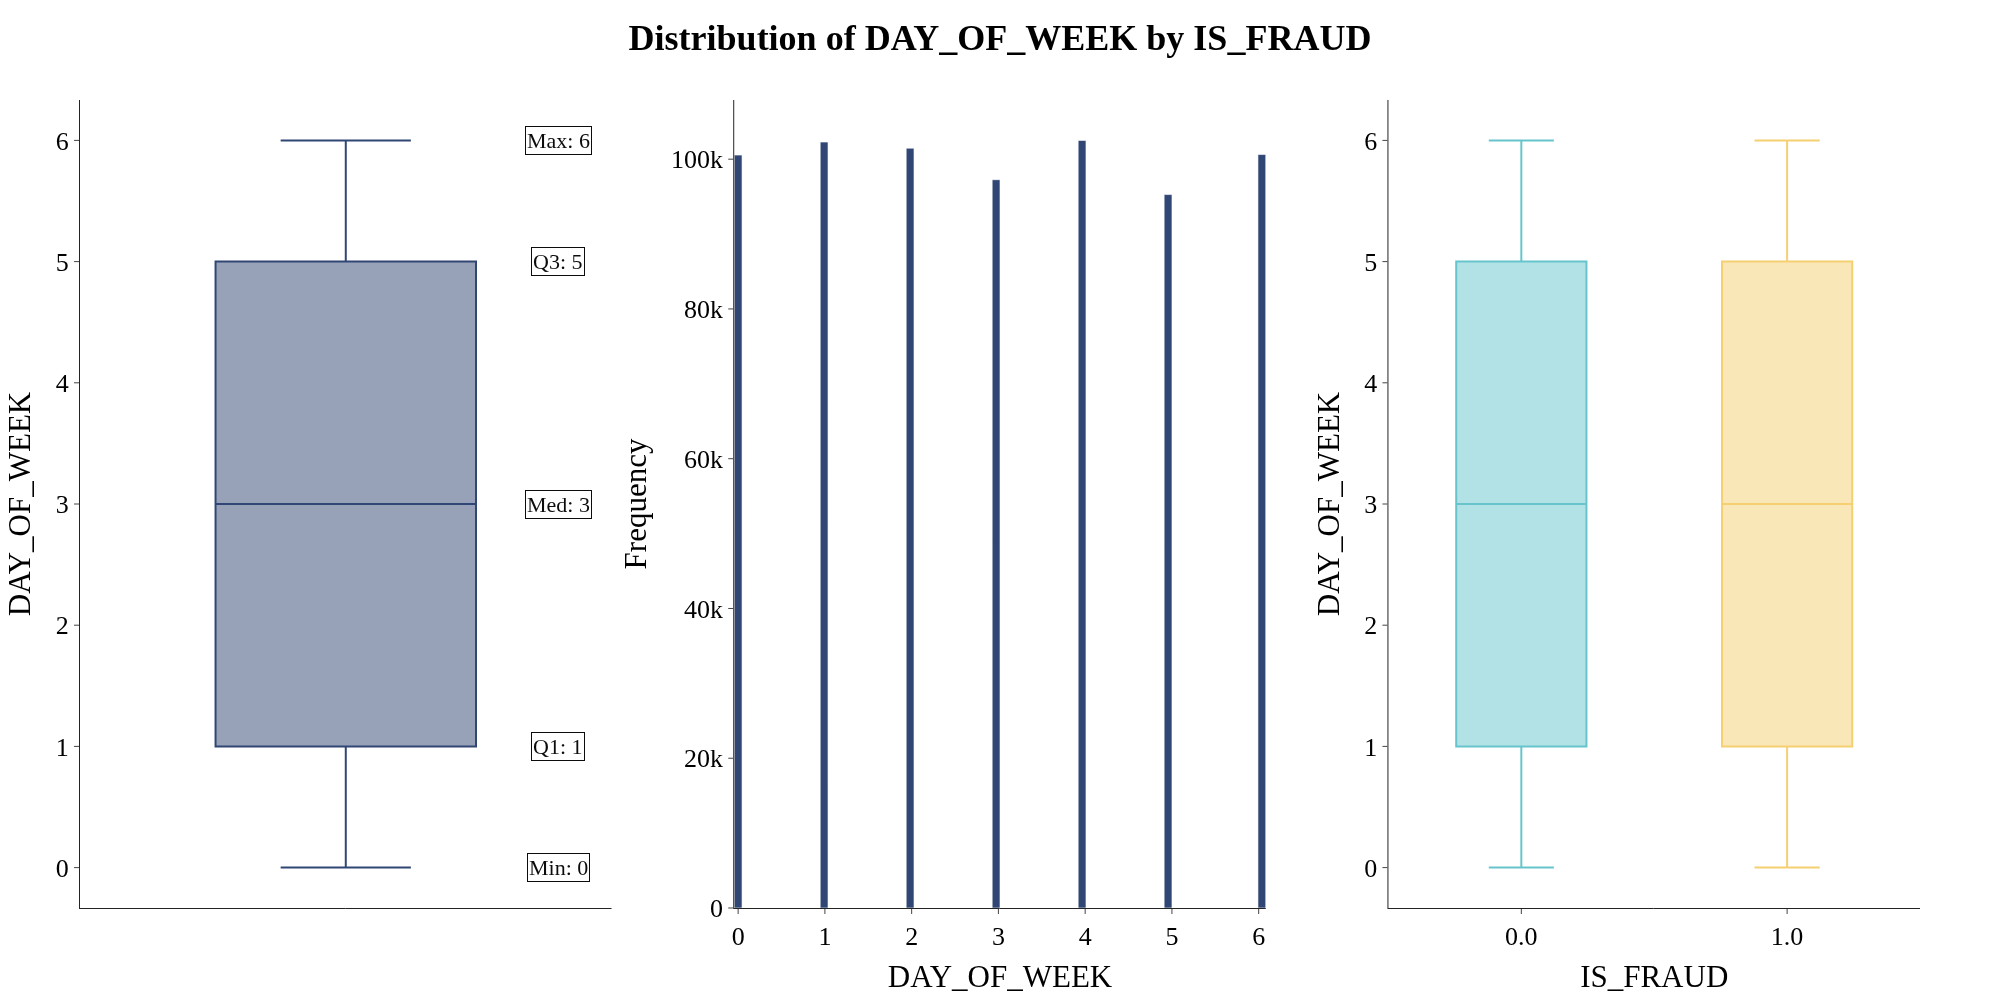

,Count,Mean,Std,Min,5%,Q1,Median,Q3,95%,Max,variance,skewness,kurtosis,Missing,Missing (%)
DAY_OF_WEEK,"699,960",2.98,2.00,0.00,0.00,1.00,3.00,5.00,6.00,6.00,4.01,0.02,-1.25,0,0.00%


In [19]:
feature = "DAY_OF_WEEK"
continuous_plots.boxplot_histogram_boxplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_numerical_feature(data, feature)

**Notes:**
- Near-uniform across the 7 days (skewness ≈ 0.02, kurtosis ≈ -1.25), each day holding 13.6-14.6% of rows, no missing values or outliers.
- No target relationship: the fraud rate ranges only from 1.58% (day 0) to 1.78% (day 6).

## `MERCHANT_RISK_SCORE`

`MERCHANT_RISK_SCORE` (float64) - A risk score assigned to the merchant, where higher values indicate a riskier merchant.

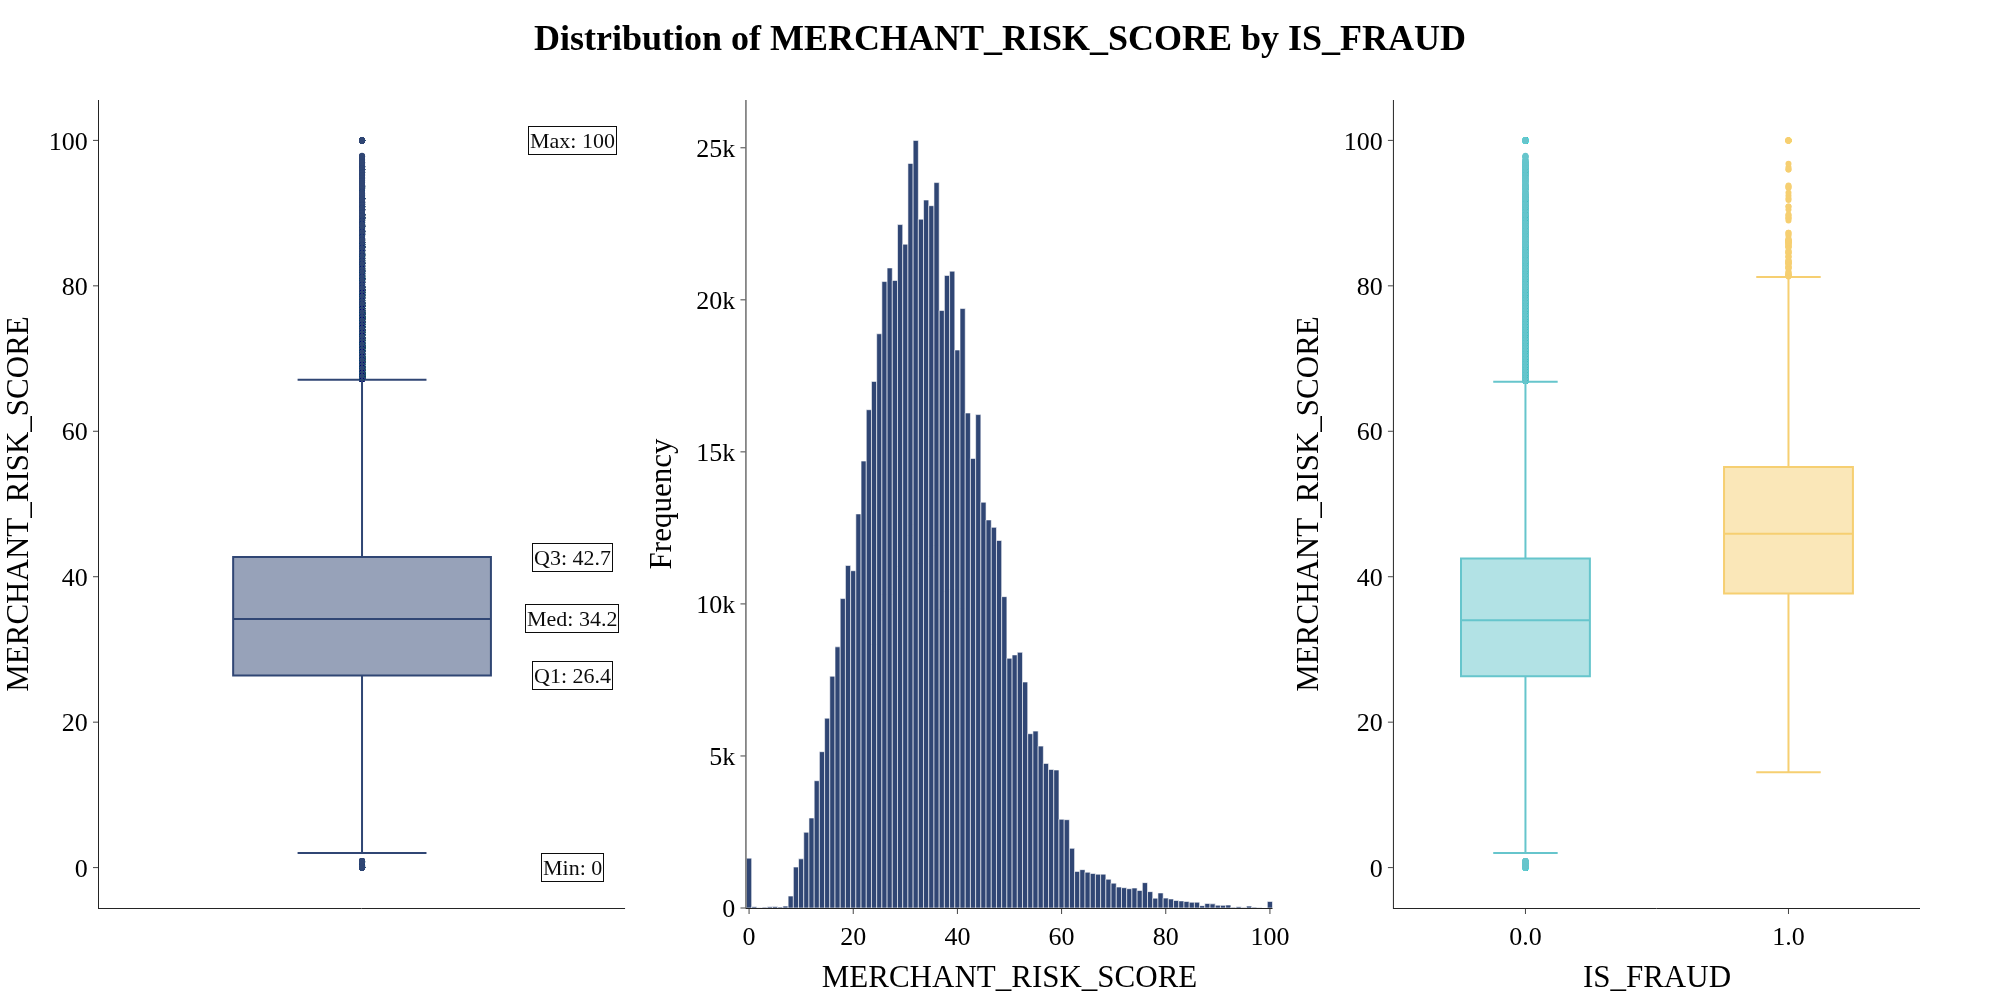

,Count,Mean,Std,Min,5%,Q1,Median,Q3,95%,Max,variance,skewness,kurtosis,Missing,Missing (%)
MERCHANT_RISK_SCORE,"699,960",35.22,12.63,0.00,16.50,26.40,34.20,42.70,57.30,100.00,159.48,0.62,0.99,0,0.00%


In [20]:
feature = "MERCHANT_RISK_SCORE"
continuous_plots.boxplot_histogram_boxplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_numerical_feature(data, feature)

**Notes:**
- Mildly right-skewed (skewness ≈ 0.62, kurtosis ≈ 0.99) from 0.00 to 100.00, median 34.20, no missing values; 13,028 rows (1.86%) lie outside the IQR bounds of 1.95-67.15 and they have a 10.00% fraud rate.
- Strongest continuous signal: fraud rate rises monotonically from 0.22% in the lowest quintile to 0.65%, 1.15%, 2.04% and 4.33% in the highest (11.75% for the top 1%, 0.00% for the bottom 1%); mean score is 47.37 for fraud vs 35.01 for legitimate.

## `PRIOR_DISPUTES`

`PRIOR_DISPUTES` (int64) - The number of disputes the customer has filed previously.

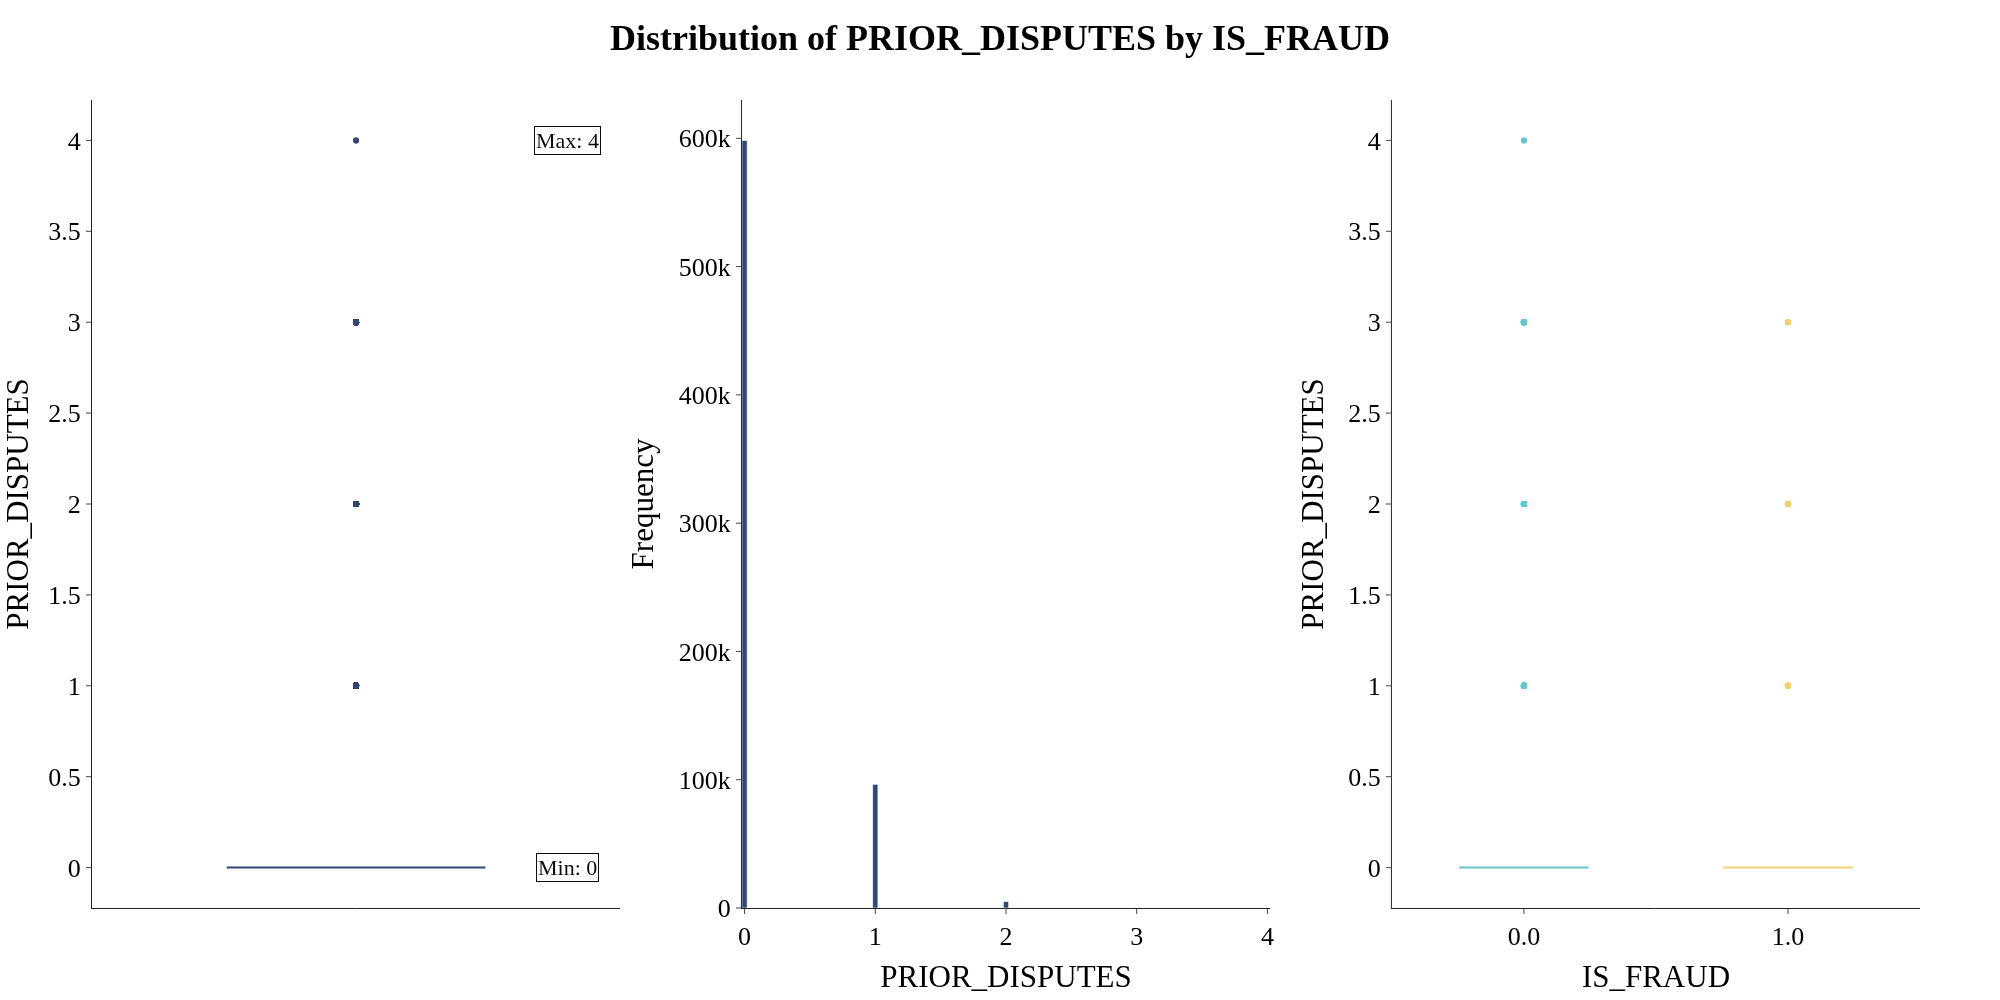

,Count,Mean,Std,Min,5%,Q1,Median,Q3,95%,Max,variance,skewness,kurtosis,Missing,Missing (%)
PRIOR_DISPUTES,"699,960",0.15,0.38,0.00,0.00,0.00,0.00,0.00,1.00,4.00,0.15,2.38,5.12,0,0.00%


In [21]:
feature = "PRIOR_DISPUTES"
continuous_plots.boxplot_histogram_boxplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_numerical_feature(data, feature)

**Notes:**
- Discrete count from 0 to 4, right-skewed (skewness ≈ 2.38, kurtosis ≈ 5.12); 85.49% of rows have 0 disputes, 13.77% have 1, 0.72% have 2, 0.02% have 3 and a handful have 4; no missing values.
- Fraud rate increases with disputes: 1.55% (0), 2.36% (1), 3.00% (2), 3.64% (3), while the single-digit-count level 4 shows 0.00%; mean is 0.222 for fraud vs 0.152 for legitimate.

**Conclusion:**
- Levels 3-4 are extremely rare and the 0.00% rate at level 4 is a small-sample artifact, so merging them into "3+" would keep the monotonic trend clean and prevent tree-based models from fitting noisy leaves.

## `MERCHANT_CATEGORY`

`MERCHANT_CATEGORY` (str) - The category of the merchant (e.g. Groceries, Gaming, Crypto Exchange, Gift Cards).

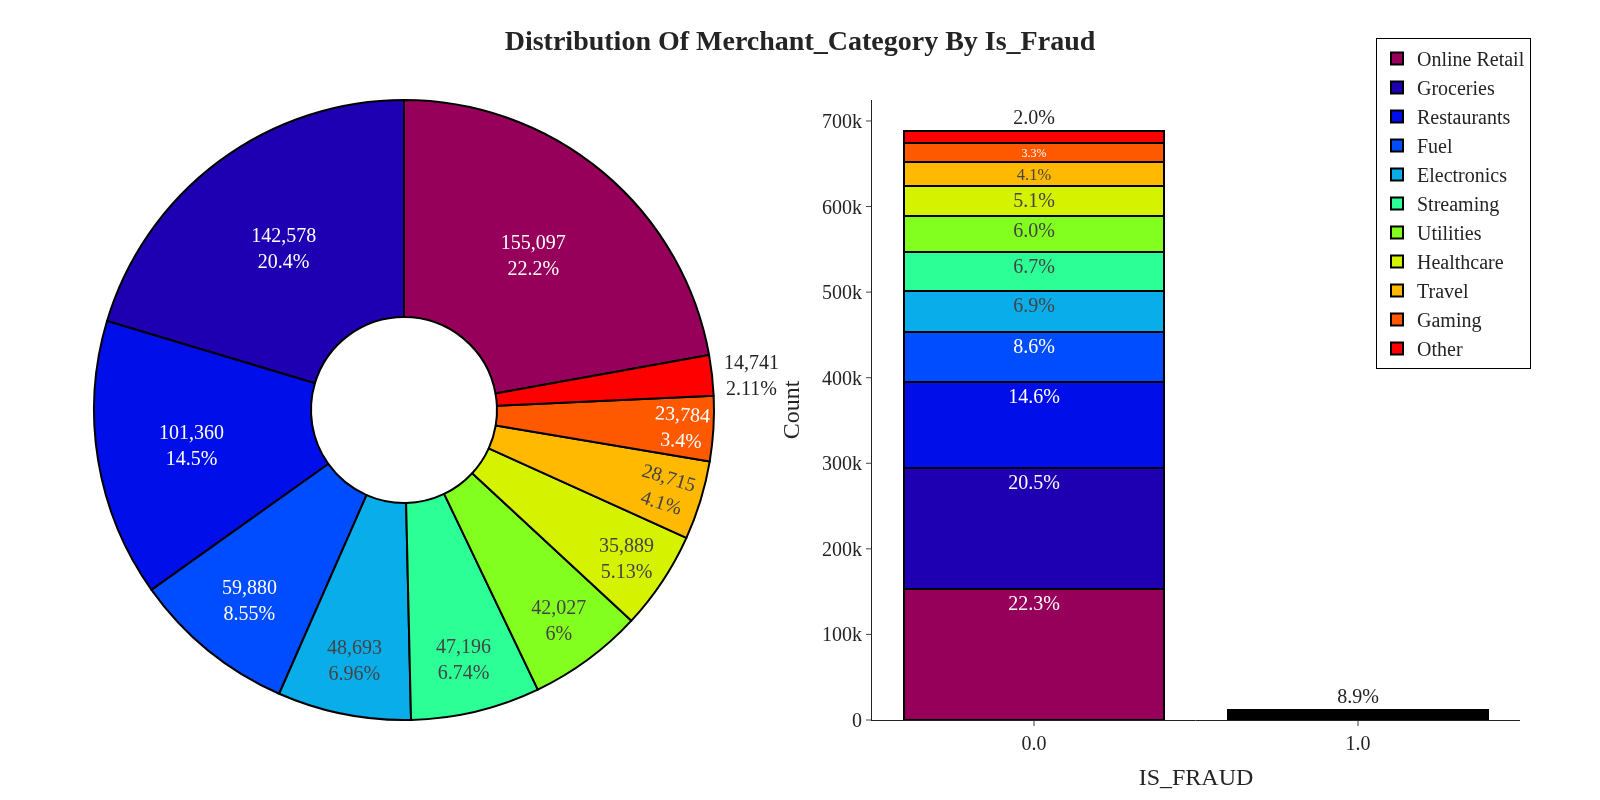

,Category,Count,Percentage (%)
0,Online Retail,"155,097",22.16%
1,Groceries,"142,578",20.37%
2,Restaurants,"101,360",14.48%
3,Fuel,"59,880",8.55%
4,Electronics,"48,693",6.96%
5,Streaming,"47,196",6.74%
6,Utilities,"42,027",6.00%
7,Healthcare,"35,889",5.13%
8,Travel,"28,715",4.10%
9,Gaming,"23,784",3.40%


In [22]:
feature = "MERCHANT_CATEGORY"
categorical_plots.pie_stacked_barplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_categorical_feature(data, feature)

**Notes:**
- 12 categories, no missing values; Online Retail (22.16%), Groceries (20.37%) and Restaurants (14.48%) dominate, while Crypto Exchange (0.76%) and Gift Cards (1.35%) are the rarest.
- Clear risk split: Gift Cards (7.30%), Crypto Exchange (6.53%), Gaming (5.51%) and Electronics (3.08%) are well above the 1.67% base rate, whereas Online Retail, Groceries, Restaurants and Fuel sit at 1.11-1.24%.

**Conclusion:**
- The categories fall into a high-risk group (Gift Cards, Crypto Exchange, Gaming, Electronics) and a low-risk group; because the riskiest categories are also the smallest, a smoothed target encoding or native categorical handling would be safer for tree-based models than one-hot encoding.

## `CARD_TYPE`

`CARD_TYPE` (str) - The card network (Visa, Mastercard, Amex, RuPay or Discover).

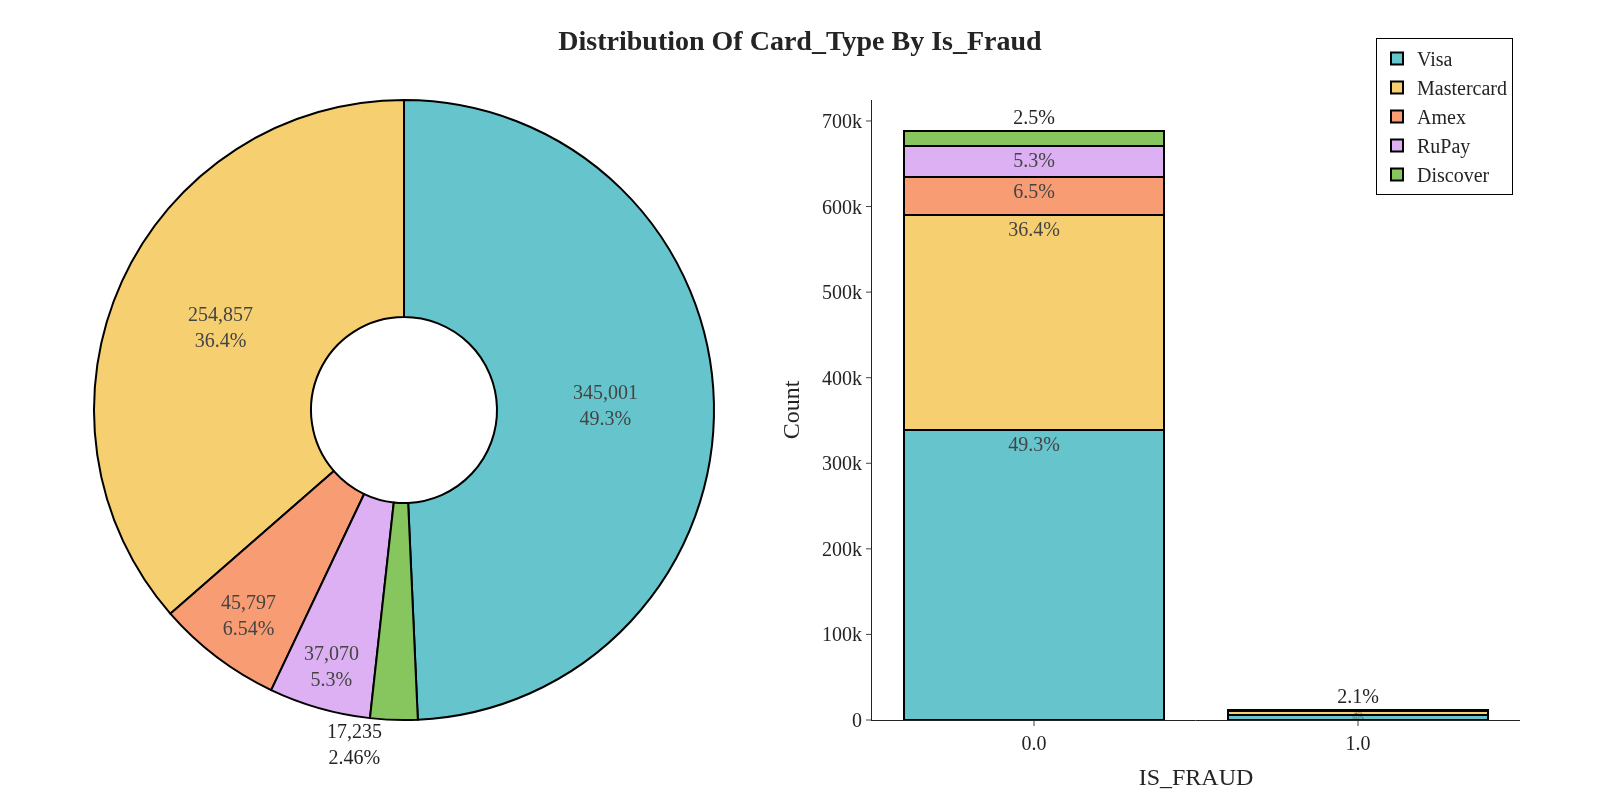

,Category,Count,Percentage (%)
0,Visa,"345,001",49.29%
1,Mastercard,"254,857",36.41%
2,Amex,"45,797",6.54%
3,RuPay,"37,070",5.30%
4,Discover,"17,235",2.46%


In [23]:
feature = "CARD_TYPE"
categorical_plots.pie_stacked_barplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_categorical_feature(data, feature)

**Notes:**
- 5 categories, no missing values; Visa (49.29%) and Mastercard (36.41%) cover 85.7% of rows, Discover is the smallest at 2.46%.
- Little target signal: fraud rate ranges only from 1.46% (Discover) to 1.90% (Amex), close to the 1.67% base rate.

## `AUTH_METHOD`

`AUTH_METHOD` (str) - The method used to authenticate the transaction (e.g. PIN, OTP, Biometric, 3D Secure, No Authentication).

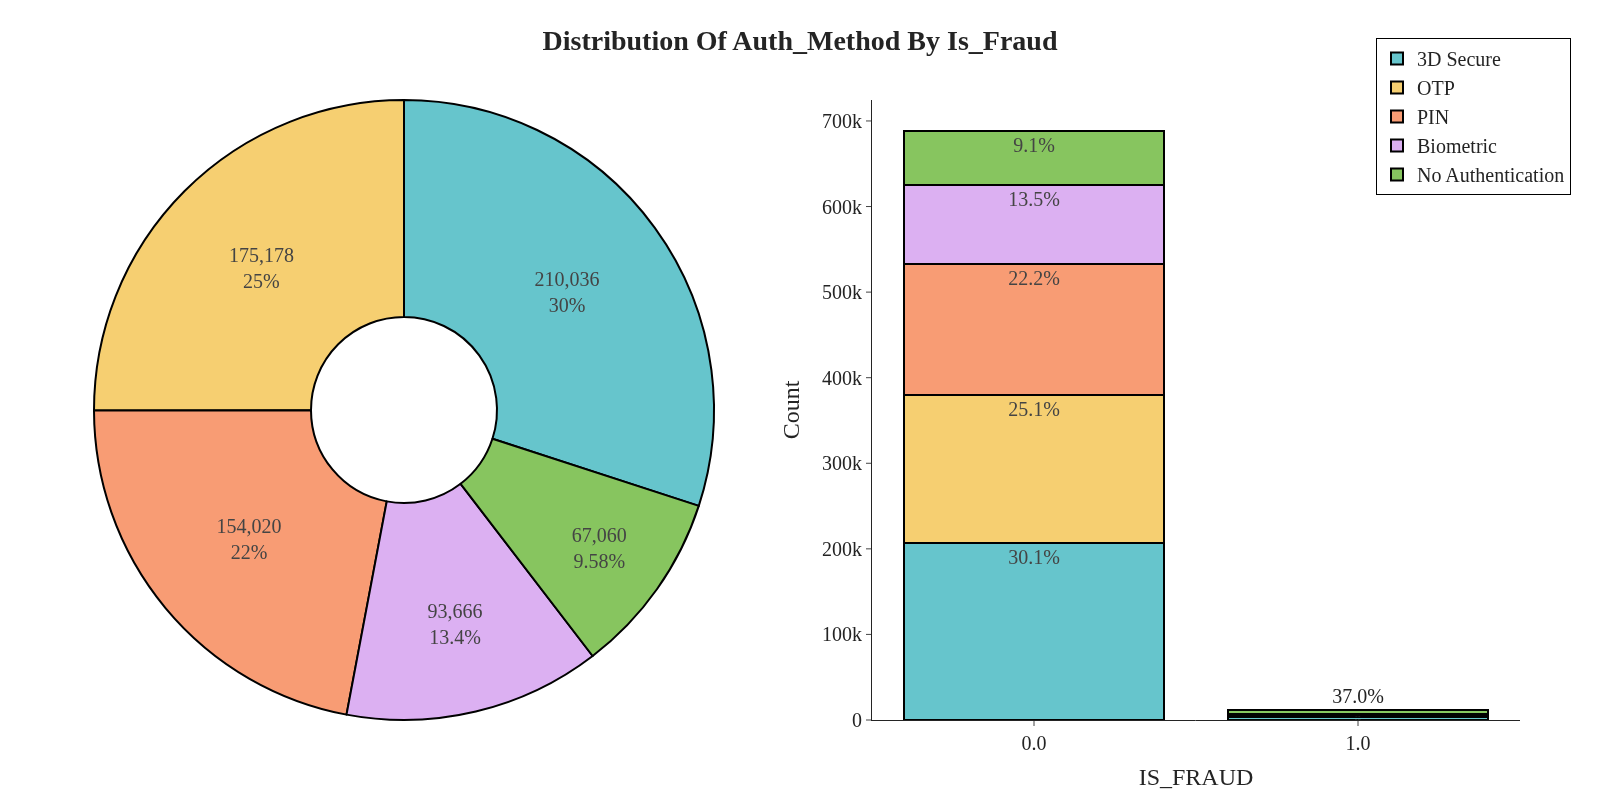

,Category,Count,Percentage (%)
0,3D Secure,"210,036",30.01%
1,OTP,"175,178",25.03%
2,PIN,"154,020",22.00%
3,Biometric,"93,666",13.38%
4,No Authentication,"67,060",9.58%


In [24]:
feature = "AUTH_METHOD"
categorical_plots.pie_stacked_barplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_categorical_feature(data, feature)

**Notes:**
- 5 categories, no missing values; 3D Secure (30.01%), OTP (25.03%) and PIN (22.00%) dominate, Biometric covers 13.38% and No Authentication 9.58%.
- Strong signal: No Authentication has a 6.44% fraud rate, versus 1.47% (3D Secure), 1.41% (OTP), 0.87% (PIN) and 0.50% (Biometric).

**Conclusion:**
- The methods have a natural security ordering (No Authentication < OTP/3D Secure < PIN < Biometric) that matches the fraud rates, so an ordinal encoding, or a dedicated "no authentication" flag, would let tree-based models isolate the high-risk group with a single split.

## `CHANNEL`

`CHANNEL` (str) - The channel through which the transaction was made (Online, POS, Contactless, In-App or ATM).

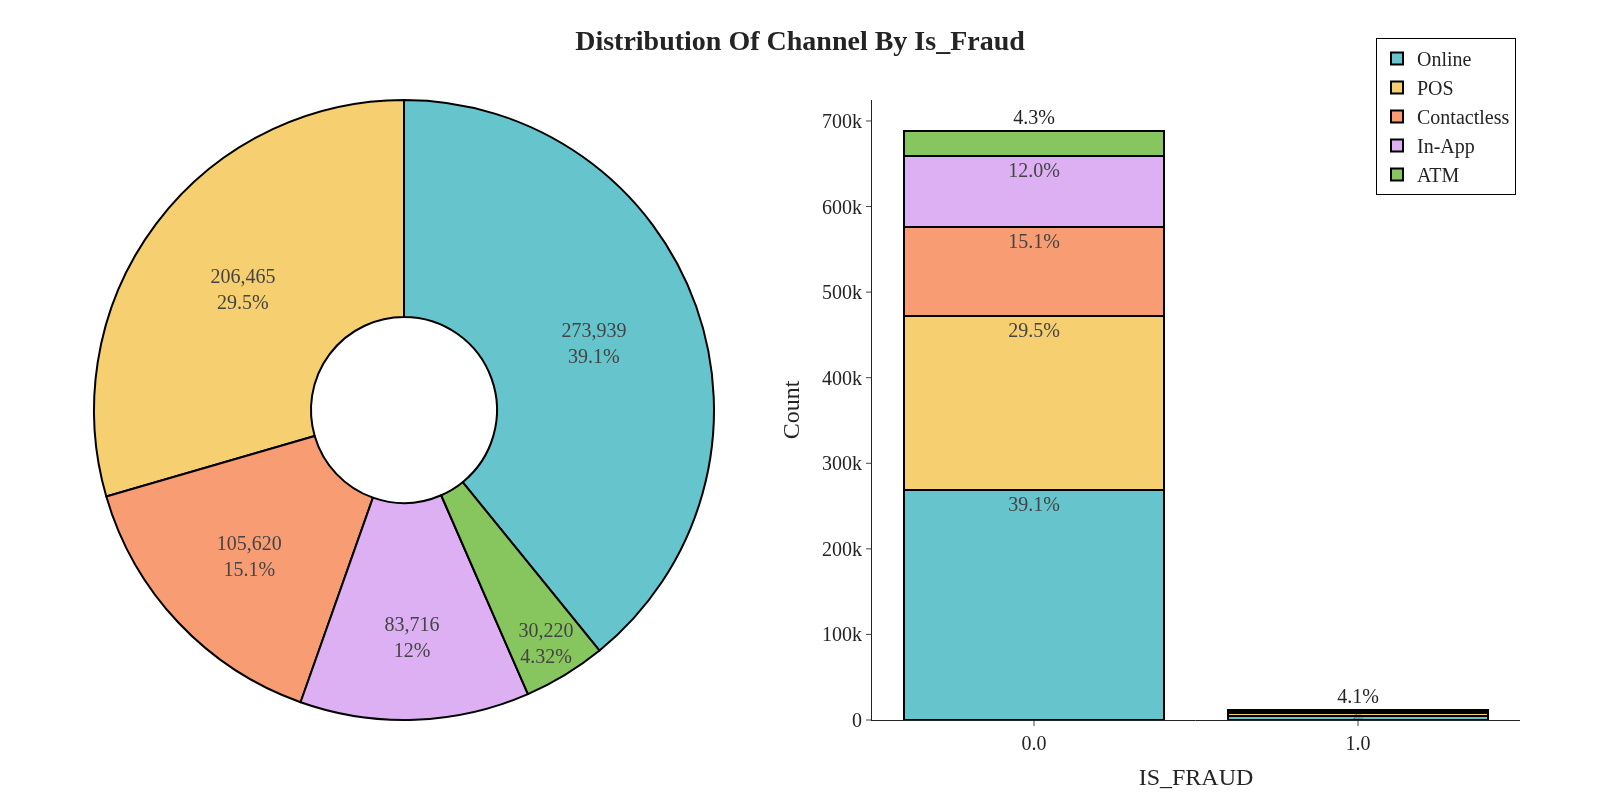

,Category,Count,Percentage (%)
0,Online,"273,939",39.14%
1,POS,"206,465",29.50%
2,Contactless,"105,620",15.09%
3,In-App,"83,716",11.96%
4,ATM,"30,220",4.32%


In [25]:
feature = "CHANNEL"
categorical_plots.pie_stacked_barplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_categorical_feature(data, feature)

**Notes:**
- 5 categories, no missing values; Online (39.14%) and POS (29.50%) dominate, ATM is the smallest at 4.32%.
- No meaningful signal: fraud rate stays within 1.55% (Contactless) to 1.74% (Online).

## `DEVICE_TYPE`

`DEVICE_TYPE` (str) - The type of device used for the transaction (e.g. Android Phone, iPhone, POS Terminal, Windows PC).

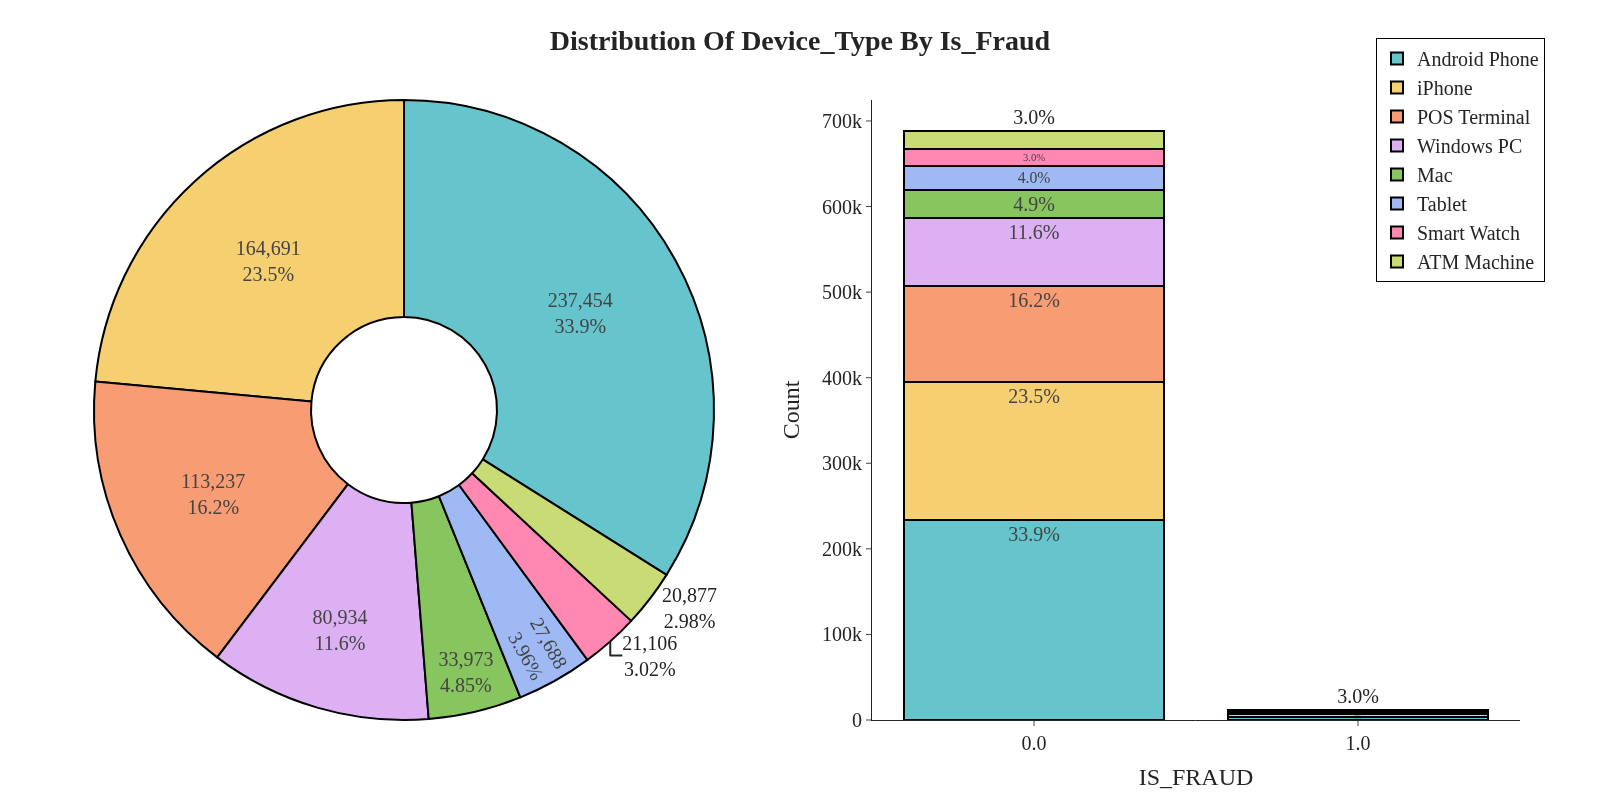

,Category,Count,Percentage (%)
0,Android Phone,"237,454",33.92%
1,iPhone,"164,691",23.53%
2,POS Terminal,"113,237",16.18%
3,Windows PC,"80,934",11.56%
4,Mac,"33,973",4.85%
5,Tablet,"27,688",3.96%
6,Smart Watch,"21,106",3.02%
7,ATM Machine,"20,877",2.98%


In [26]:
feature = "DEVICE_TYPE"
categorical_plots.pie_stacked_barplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_categorical_feature(data, feature)

**Notes:**
- 8 categories, no missing values; Android Phone (33.92%) and iPhone (23.53%) lead, the smallest are ATM Machine (2.98%) and Smart Watch (3.02%).
- No meaningful signal: fraud rate stays within 1.61% (Android Phone, Windows PC) to 1.73% (POS Terminal).

## `IS_FOREIGN_TRANSACTION`

`IS_FOREIGN_TRANSACTION` (int64) - Binary flag indicating whether the transaction was made abroad.

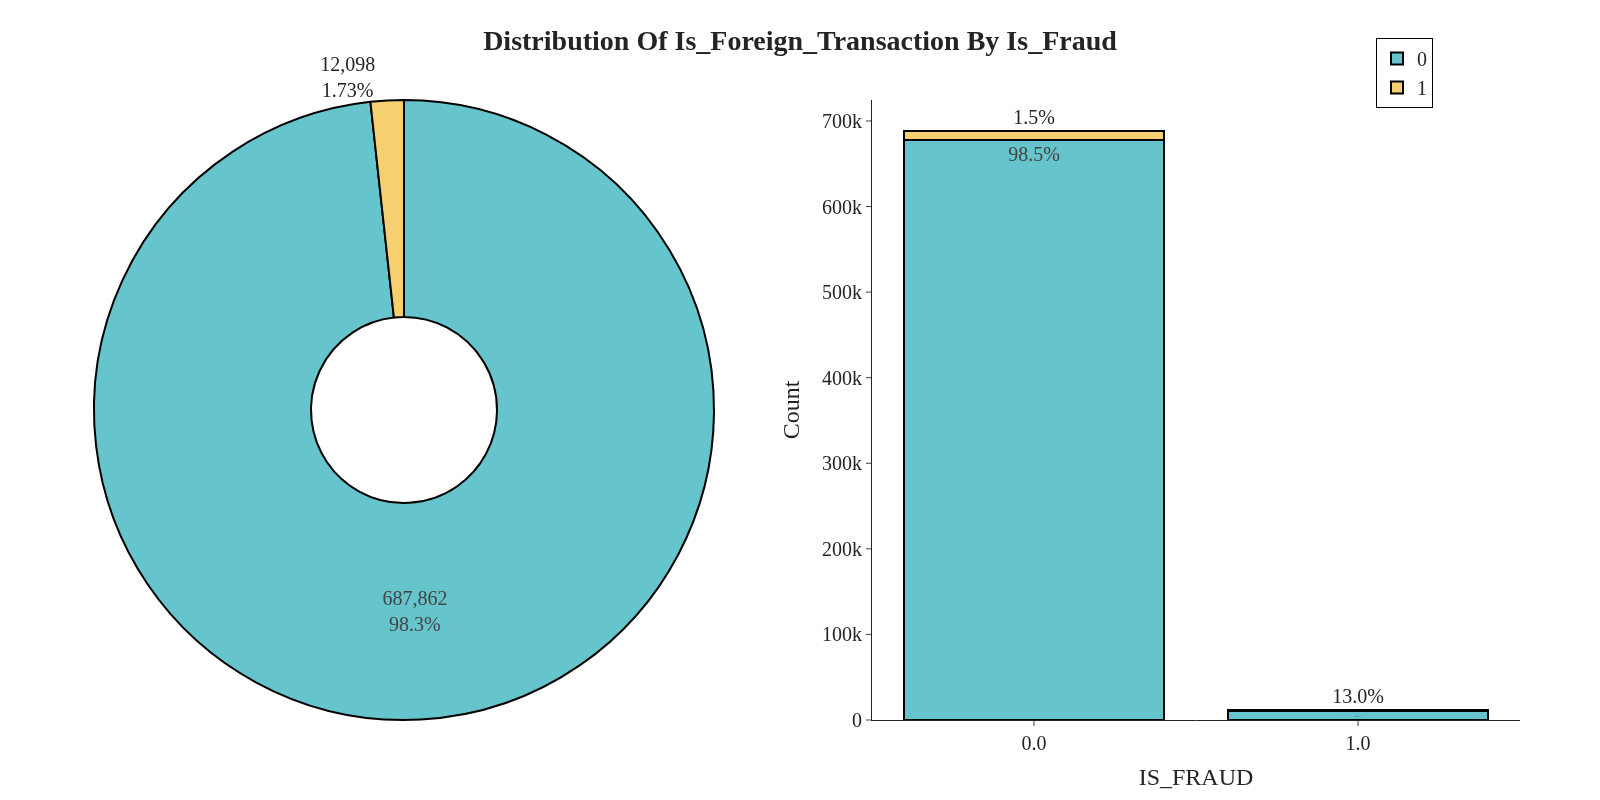

,Category,Count,Percentage (%)
0,0,"687,862",98.27%
1,1,"12,098",1.73%


In [27]:
feature = "IS_FOREIGN_TRANSACTION"
categorical_plots.pie_stacked_barplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_categorical_feature(data, feature)

**Notes:**
- Binary flag, no missing values; only 1.73% of transactions are foreign.
- Strong signal: fraud rate is 12.57% for foreign transactions vs 1.48% for domestic, about 7.5x the base rate.

## `IS_NEW_MERCHANT`

`IS_NEW_MERCHANT` (int64) - Binary flag indicating whether the cardholder is transacting with this merchant for the first time.

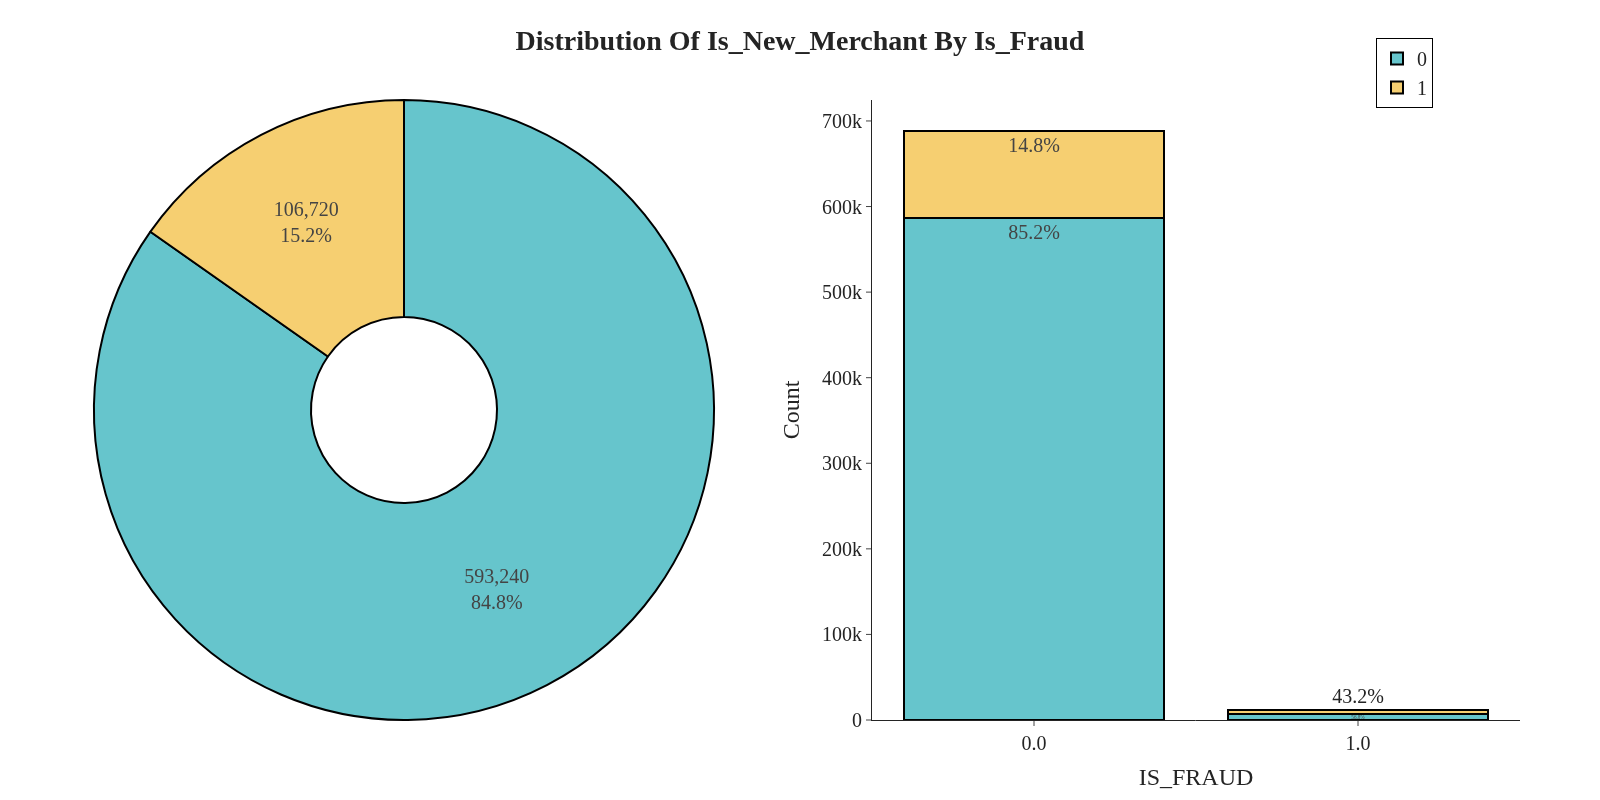

,Category,Count,Percentage (%)
0,0,"593,240",84.75%
1,1,"106,720",15.25%


In [28]:
feature = "IS_NEW_MERCHANT"
categorical_plots.pie_stacked_barplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_categorical_feature(data, feature)

**Notes:**
- Binary flag, no missing values; 15.25% of transactions are with a new merchant.
- Fraud rate is 4.73% with a new merchant vs 1.12% with a known one, about 4.2x higher.

## `USED_VPN`

`USED_VPN` (int64) - Binary flag indicating whether a VPN was used for the transaction.

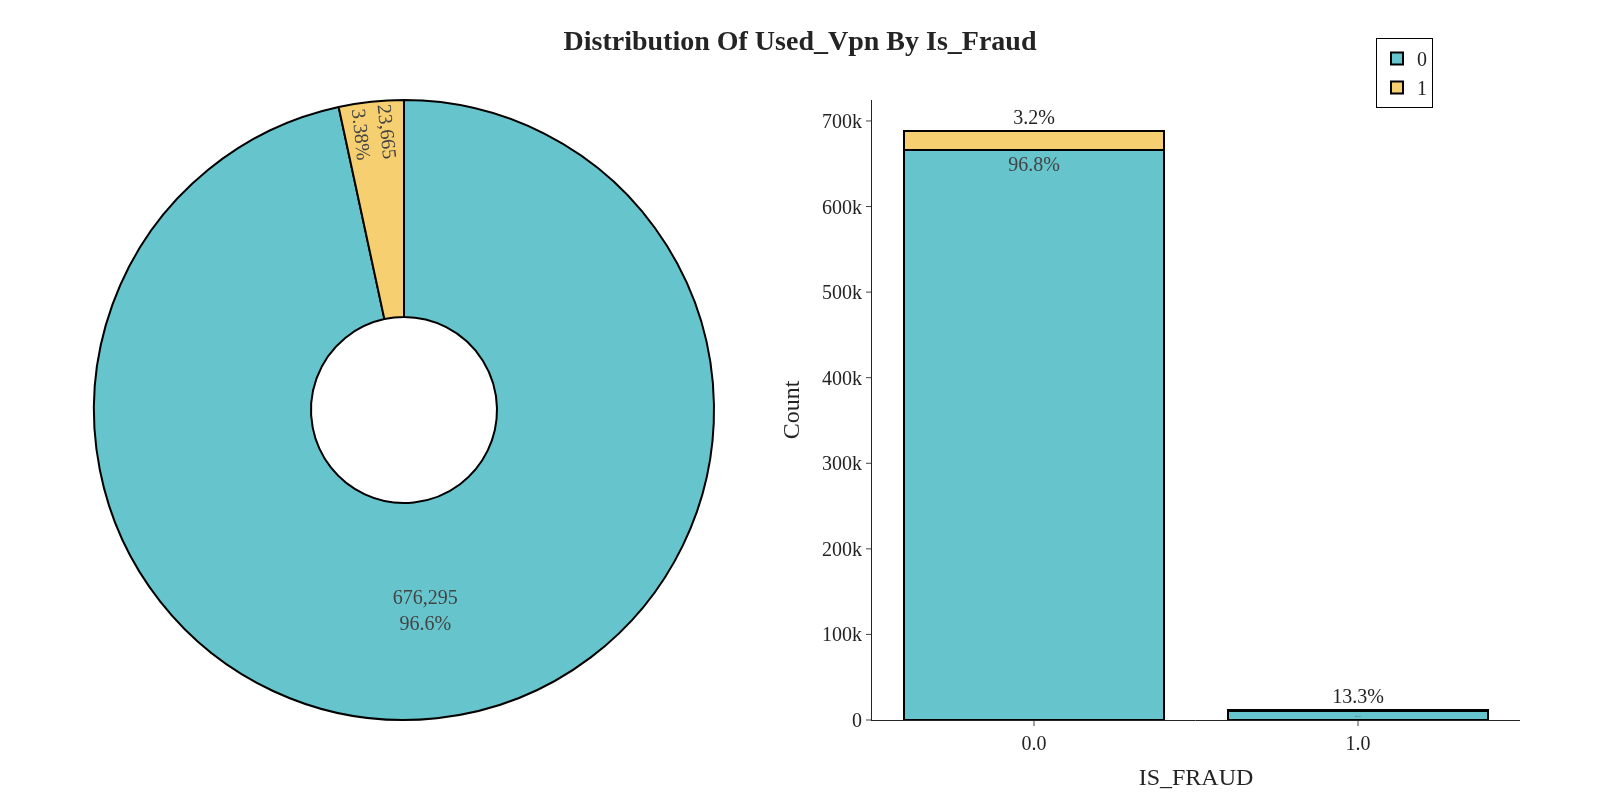

,Category,Count,Percentage (%)
0,0,"676,295",96.62%
1,1,"23,665",3.38%


In [29]:
feature = "USED_VPN"
categorical_plots.pie_stacked_barplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_categorical_feature(data, feature)

**Notes:**
- Binary flag, no missing values; a VPN was used in 3.38% of transactions.
- Fraud rate is 6.55% with a VPN vs 1.50% without, about 4.4x higher.

## `IP_COUNTRY_MISMATCH`

`IP_COUNTRY_MISMATCH` (int64) - Binary flag indicating whether the IP address country differs from the card's country.

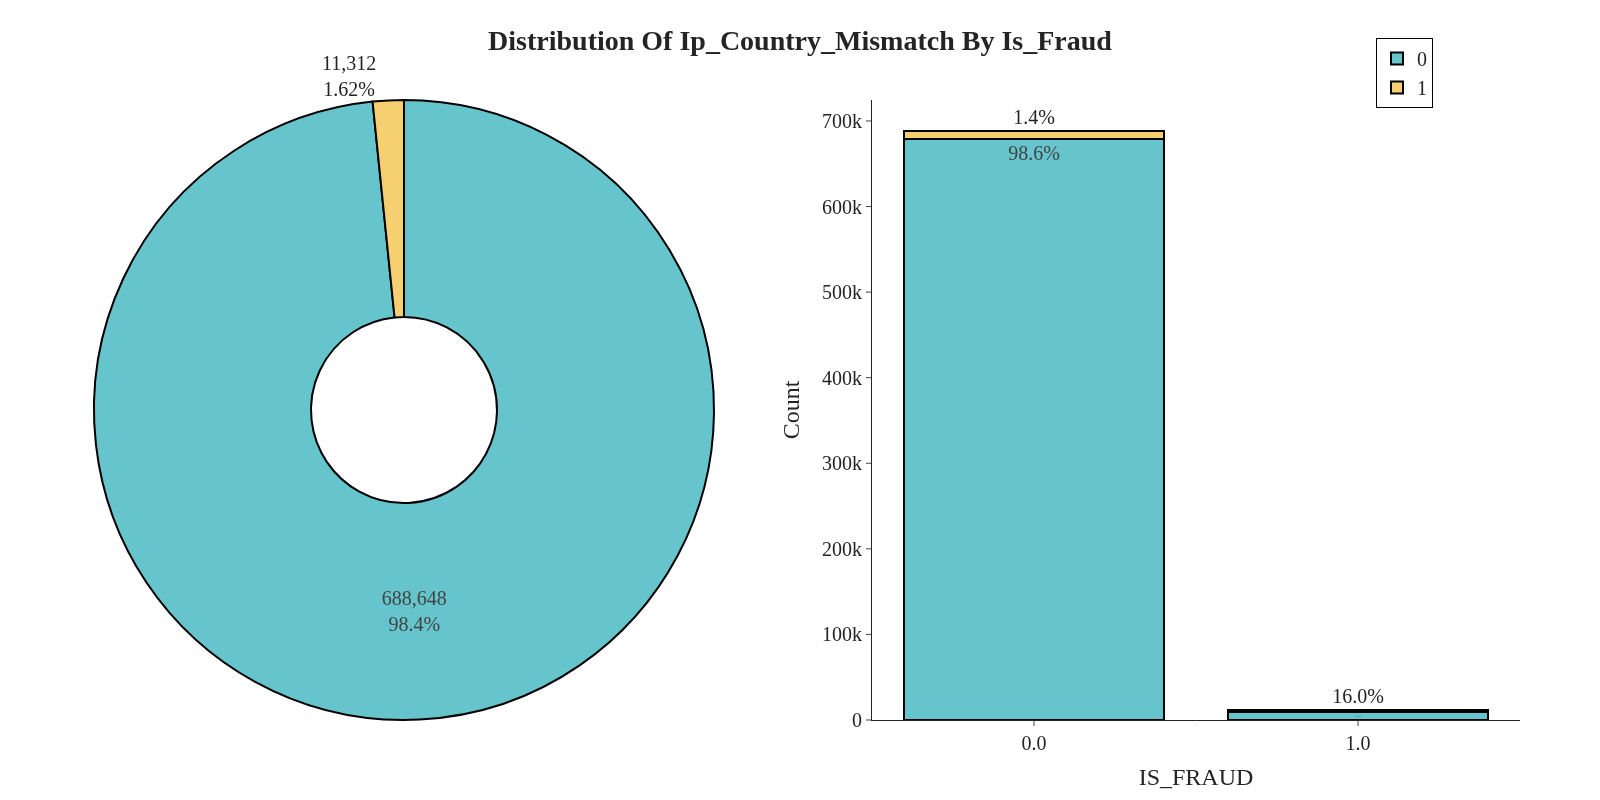

,Category,Count,Percentage (%)
0,0,"688,648",98.38%
1,1,"11,312",1.62%


In [30]:
feature = "IP_COUNTRY_MISMATCH"
categorical_plots.pie_stacked_barplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_categorical_feature(data, feature)

**Notes:**
- Binary flag, no missing values; a mismatch occurs in 1.62% of transactions.
- The strongest of the binary flags: fraud rate is 16.50% on mismatch vs 1.43% otherwise, about 11.5x higher.

## `BILLING_SHIPPING_MISMATCH`

`BILLING_SHIPPING_MISMATCH` (int64) - Binary flag indicating whether the billing and shipping addresses differ.

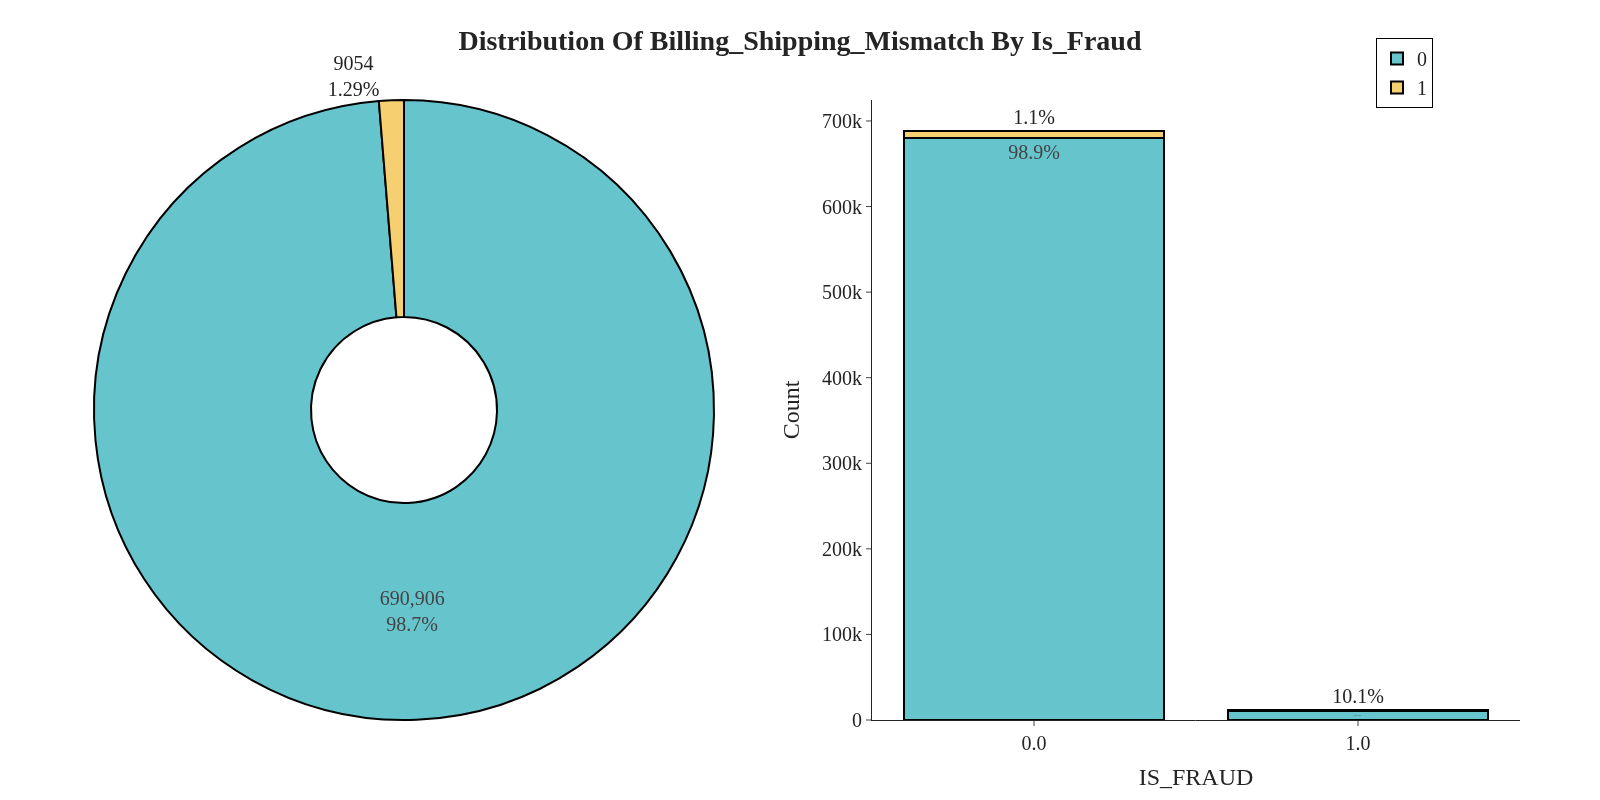

,Category,Count,Percentage (%)
0,0,"690,906",98.71%
1,1,"9,054",1.29%


In [31]:
feature = "BILLING_SHIPPING_MISMATCH"
categorical_plots.pie_stacked_barplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_categorical_feature(data, feature)

**Notes:**
- Binary flag, no missing values; a mismatch occurs in 1.29% of transactions.
- Fraud rate is 12.99% on mismatch vs 1.52% otherwise, about 8.5x higher.

## `IS_AI_GENERATED_SCAM_ATTEMPT`

`IS_AI_GENERATED_SCAM_ATTEMPT` (int64) - Binary flag indicating whether the transaction was flagged as an AI-generated scam attempt.

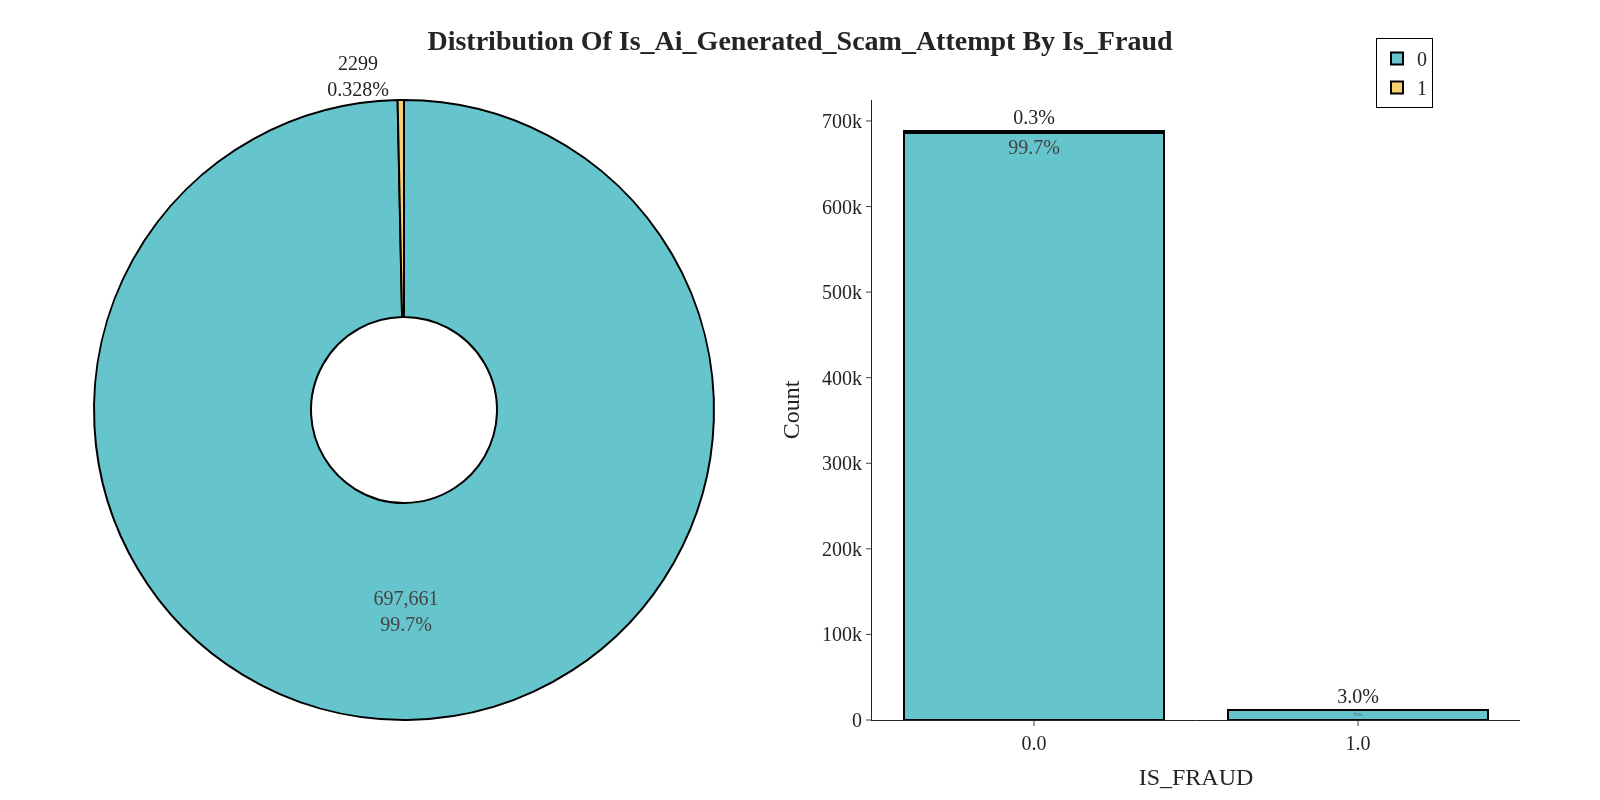

,Category,Count,Percentage (%)
0,0,"697,661",99.67%
1,1,"2,299",0.33%


In [32]:
feature = "IS_AI_GENERATED_SCAM_ATTEMPT"
categorical_plots.pie_stacked_barplot_by_hue(data, feature, TARGET_FEATURE, plot_title=f"Distribution of {feature} by {TARGET_FEATURE}")
data_analyzer.describe_categorical_feature(data, feature)

**Notes:**
- Binary flag, no missing values; only 0.33% of transactions are flagged as AI-generated scam attempts, the rarest of the six binary flags.
- Fraud rate is 15.22% for flagged transactions vs 1.63% otherwise, about 9.3x higher.

**Conclusion:**
- The six binary flags (foreign, new merchant, VPN, IP mismatch, billing mismatch, AI scam) are individually rare but each raises fraud rate 4-11x, so a summed risk-flag count would give tree-based models a compact signal for rows where several flags co-occur instead of requiring deep multi-flag splits.

## Data preparation for Multivariate analysis

In [33]:
def get_feature_groups(
    data: pd.DataFrame, target_feature: str
) -> tuple[list[str], list[str], list[str]]:
    """
    Splits a DataFrame's columns into independent, categorical, and numerical feature groups.

    Args:
        data (pd.DataFrame): The full dataset, including the target column.
        target_feature (str): Name of the target column to exclude from the feature groups.

    Returns:
        tuple[list[str], list[str], list[str]]: Independent, categorical, and numerical features.

    Raises:
        AssertionError: If categorical and numerical features do not together cover all
            independent features.
    """
    independent_feats = data.drop(columns=[target_feature]).columns.tolist()
    categorical_feats = find_categorical_variables(data[independent_feats], return_empty=True)
    numerical_feats = find_numerical_variables(data[independent_feats], return_empty=True)

    if set(categorical_feats) | set(numerical_feats) != set(independent_feats):
        raise AssertionError(
            "Categorical and numerical features do not cover all independent features."
        )

    return independent_feats, categorical_feats, numerical_feats

independent_features, categorical_features, numerical_features = get_feature_groups(train_data, TARGET_FEATURE)

In [34]:
imputation_pipeline = Pipeline(
    steps=[
        (
            "case_normalizer",
            CaseNormalizer(features_names=categorical_features, normalization="upper"),
        ),
        (
            "categorical_aligner",
            CategoricalAligner(
                variables=categorical_features,
                fill_strategy="constant",
                default_value="MISSING",
                warn_on_unknown=False
            ),
        ),
        (
            "median_imputer",
            MeanMedianImputer(
                variables=numerical_features,
                imputation_method='median')
        ),
        (
            "numerical_downcaster",
            NumericalDowncaster()
        )
    ]
)

train_data[independent_features] = imputation_pipeline.fit_transform(train_data[independent_features])
test_data[independent_features] = imputation_pipeline.transform(test_data[independent_features])

## Mutual information

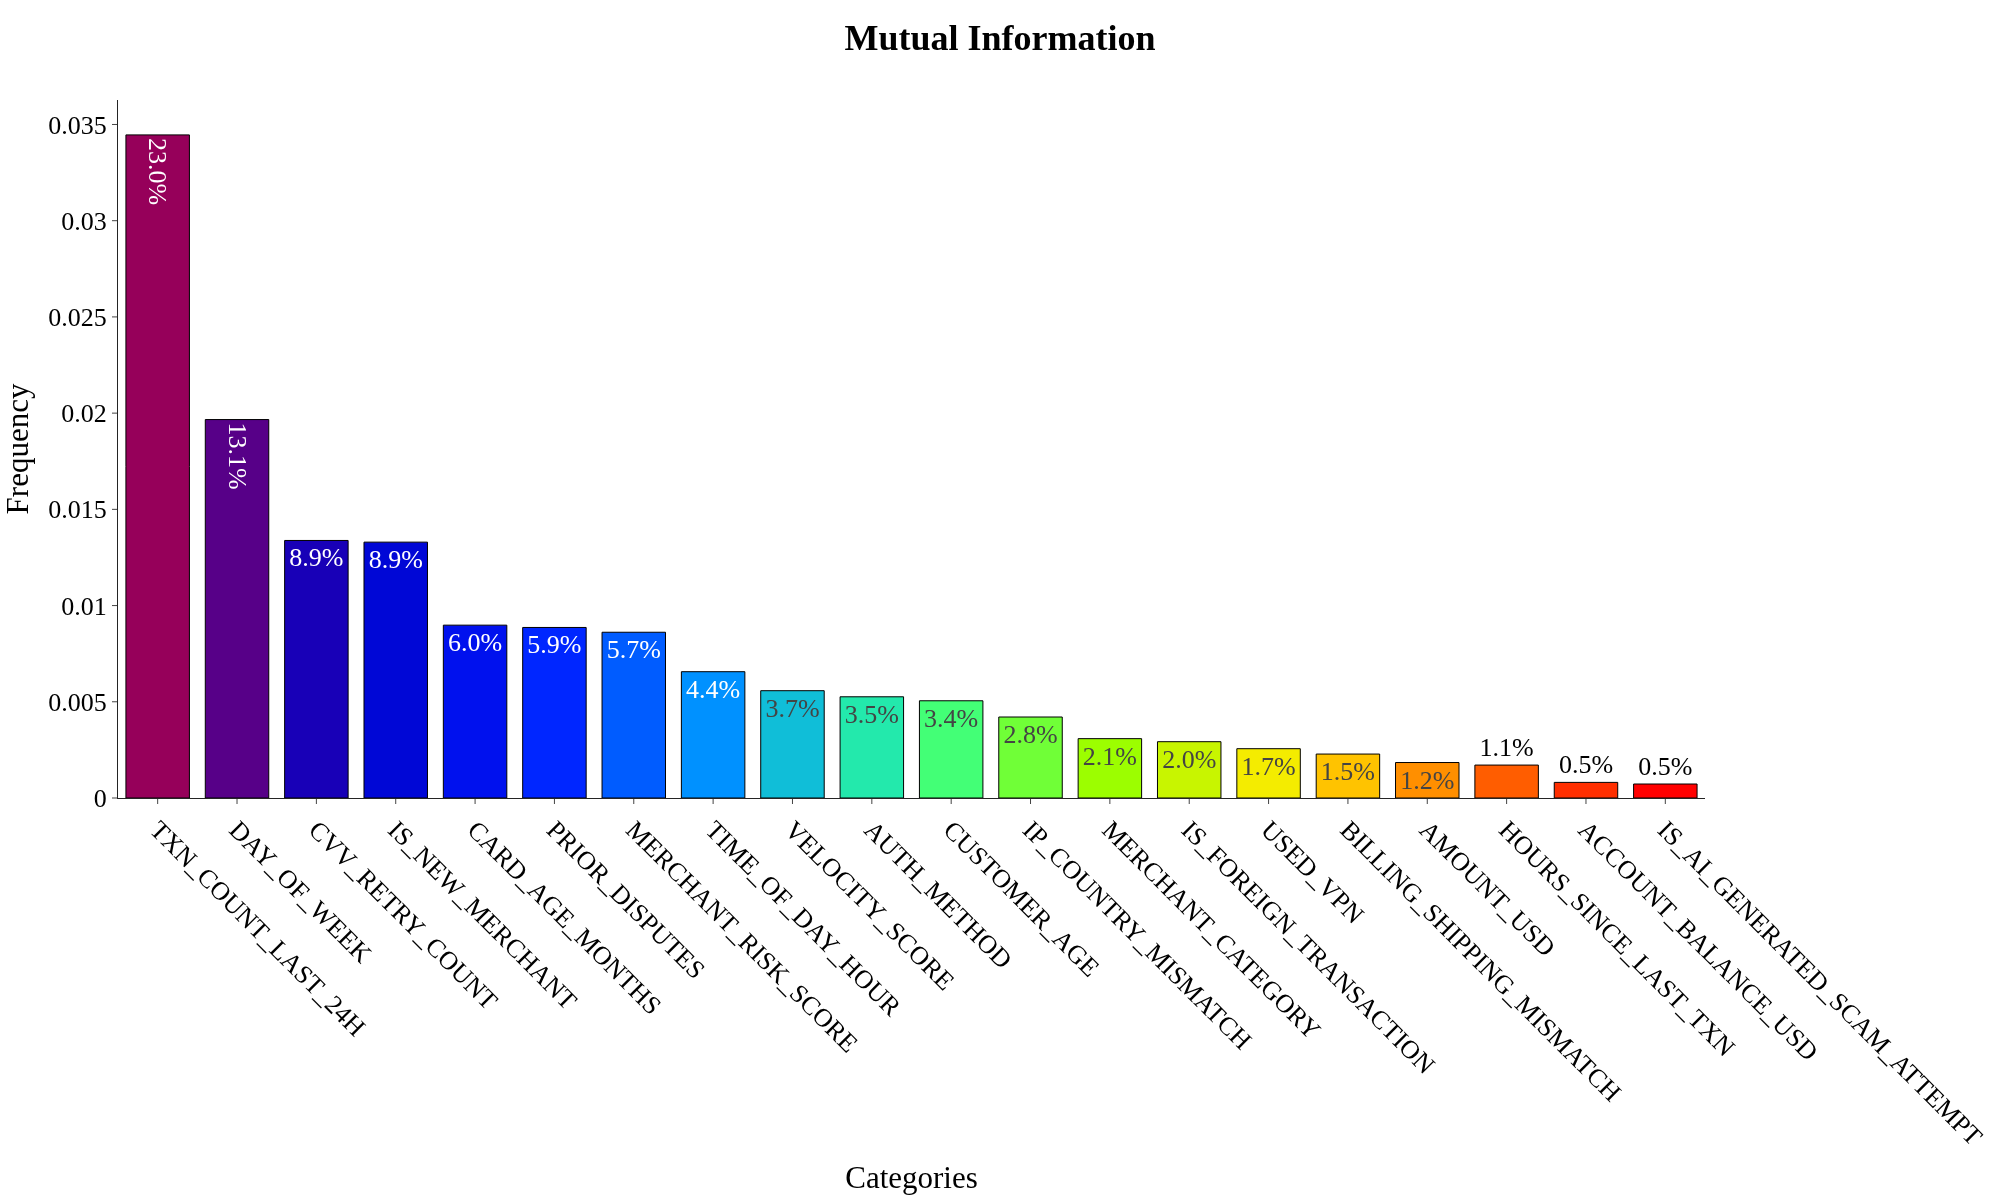

In [35]:
mi_scores = data_analyzer.mutual_information_scores(train_data[independent_features], train_data[TARGET_FEATURE], problem_type=PROBLEM_TYPE)
categorical_plots.barplot(mi_scores, plot_title="Mutual Information", top_n=20, show_other=False, tickangle=45, width=2000, height=1200)

# Statistical analysis

## Numerical features

In [36]:
numerical_features = [
    col for col in train_data.select_dtypes(include=[np.number]).columns if col != TARGET_FEATURE
]
data_analyzer.numerical_feature_statistics(train_data, numerical_features)

,Feature,Min,Mean,Median,Max,Std,Skewness,Kurtosis,Outliers IQR (%),Flags
0,AMOUNT_USD,1.000,79.893,27.250,6872.690,205.174,7.002,97.266,70741 (10.11%),HIGH RIGHT SKEW; HEAVY TAILS
1,HOURS_SINCE_LAST_TXN,0.010,6.634,4.730,51.980,6.290,1.823,4.402,32816 (4.69%),HIGH RIGHT SKEW; HEAVY TAILS
2,TXN_COUNT_LAST_24H,0.000,2.984,3.000,11.000,1.499,0.436,0.106,2704 (0.39%),
3,DISTANCE_FROM_HOME_KM,0.000,13.588,10.220,57.930,11.617,1.060,0.450,16770 (2.40%),HIGH RIGHT SKEW
4,CARD_AGE_MONTHS,25.000,46.863,47.000,73.000,5.579,0.133,-0.019,2253 (0.32%),
5,CUSTOMER_AGE,18.000,51.430,52.000,81.000,17.899,-0.141,-1.046,0 (0.00%),
6,ACCOUNT_BALANCE_USD,58.250,2064.998,1382.740,99701.390,3400.133,14.436,278.354,29068 (4.15%),HIGH RIGHT SKEW; HEAVY TAILS
7,CVV_RETRY_COUNT,0.000,0.085,0.000,3.000,0.290,3.319,10.534,57872 (8.27%),HIGH RIGHT SKEW; ZERO-INFLATED; HEAVY TAILS
8,VELOCITY_SCORE,0.000,18.929,18.600,72.900,10.864,0.260,-0.145,4276 (0.61%),ZERO-INFLATED
9,TIME_OF_DAY_HOUR,0.000,11.762,12.000,23.000,6.869,-0.056,-1.184,0 (0.00%),


In [37]:
for feature in numerical_features:
    display(data_analyzer.describe_feature_by_target(train_data, feature=feature, target=TARGET_FEATURE, problem_type=PROBLEM_TYPE))

,Target,Count,Mean,Std,Min,Q25,Median,Q75,Max,Skewness,Missing (%)
0,0.000000,"688,271",79.373,204.166,1.000,15.770,27.210,42.950,6872.690,6.997,0.00%
1,1.000000,"11,689",110.505,255.808,1.000,16.770,31.180,49.890,6078.290,6.772,0.00%
2,Overall,"699,960",79.893,205.174,1.000,15.810,27.250,43.110,6872.690,7.002,0.00%


,Target,Count,Mean,Std,Min,Q25,Median,Q75,Max,Skewness,Missing (%)
0,0.000000,"688,271",6.651,6.292,0.010,2.120,4.730,9.220,51.980,1.821,0.00%
1,1.000000,"11,689",5.645,6.117,0.010,1.400,3.610,7.820,48.100,2.027,0.00%
2,Overall,"699,960",6.634,6.290,0.010,2.110,4.730,9.190,51.980,1.823,0.00%


,Target,Count,Mean,Std,Min,Q25,Median,Q75,Max,Skewness,Missing (%)
0,0.000000,"688,271",2.973,1.496,0.000,2.000,3.000,4.000,11.000,0.435,0.00%
1,1.000000,"11,689",3.652,1.551,0.000,3.000,4.000,5.000,11.000,0.458,0.00%
2,Overall,"699,960",2.984,1.499,0.000,2.000,3.000,4.000,11.000,0.436,0.00%


,Target,Count,Mean,Std,Min,Q25,Median,Q75,Max,Skewness,Missing (%)
0,0.000000,"688,271",13.585,11.616,0.000,4.430,10.220,19.740,57.930,1.060,0.00%
1,1.000000,"11,689",13.750,11.712,0.010,4.440,10.310,20.170,52.770,1.050,0.00%
2,Overall,"699,960",13.588,11.617,0.000,4.430,10.220,19.750,57.930,1.060,0.00%


,Target,Count,Mean,Std,Min,Q25,Median,Q75,Max,Skewness,Missing (%)
0,0.000000,"688,271",46.862,5.580,25.000,43.000,47.000,51.000,73.000,0.133,0.00%
1,1.000000,"11,689",46.892,5.536,28.000,43.000,47.000,50.000,72.000,0.125,0.00%
2,Overall,"699,960",46.863,5.579,25.000,43.000,47.000,51.000,73.000,0.133,0.00%


,Target,Count,Mean,Std,Min,Q25,Median,Q75,Max,Skewness,Missing (%)
0,0.000000,"688,271",51.300,17.909,18.000,38.000,52.000,66.000,81.000,-0.133,0.00%
1,1.000000,"11,689",59.129,15.504,18.000,48.000,61.000,73.000,81.000,-0.507,0.00%
2,Overall,"699,960",51.430,17.899,18.000,38.000,52.000,66.000,81.000,-0.141,0.00%


... (9 outputs left out)

,Target,Count,Mean,Std,Min,Q25,Median,Q75,Max,Skewness,Missing (%)
0,0.000000,"688,271",0.032,0.176,0.000,0.000,0.000,0.000,1.000,5.306,0.00%
1,1.000000,"11,689",0.133,0.339,0.000,0.000,0.000,0.000,1.000,2.167,0.00%
2,Overall,"699,960",0.034,0.181,0.000,0.000,0.000,0.000,1.000,5.159,0.00%


,Target,Count,Mean,Std,Min,Q25,Median,Q75,Max,Skewness,Missing (%)
0,0.000000,"688,271",0.014,0.116,0.000,0.000,0.000,0.000,1.000,8.359,0.00%
1,1.000000,"11,689",0.160,0.366,0.000,0.000,0.000,0.000,1.000,1.859,0.00%
2,Overall,"699,960",0.016,0.126,0.000,0.000,0.000,0.000,1.000,7.674,0.00%


,Target,Count,Mean,Std,Min,Q25,Median,Q75,Max,Skewness,Missing (%)
0,0.000000,"688,271",0.011,0.106,0.000,0.000,0.000,0.000,1.000,9.186,0.00%
1,1.000000,"11,689",0.101,0.301,0.000,0.000,0.000,0.000,1.000,2.656,0.00%
2,Overall,"699,960",0.013,0.113,0.000,0.000,0.000,0.000,1.000,8.621,0.00%


,Target,Count,Mean,Std,Min,Q25,Median,Q75,Max,Skewness,Missing (%)
0,0.000000,"688,271",0.003,0.053,0.000,0.000,0.000,0.000,1.000,18.712,0.00%
1,1.000000,"11,689",0.030,0.170,0.000,0.000,0.000,0.000,1.000,5.517,0.00%
2,Overall,"699,960",0.003,0.057,0.000,0.000,0.000,0.000,1.000,17.363,0.00%


In [38]:
data_analyzer.numerical_target_association(train_data, numerical_features, target=TARGET_FEATURE, problem_type=PROBLEM_TYPE)

,Feature,0.0 Median,0.0 IQR,1.0 Median,1.0 IQR,η²,ε²,KW p-value,Median Range / IQR
0,CVV_RETRY_COUNT,0.00000,0.00000,0.00000,1.00000,0.04507,0.03749,0.000e+00,0.00000
1,IP_COUNTRY_MISMATCH,0.00000,0.00000,0.00000,0.00000,0.02199,0.02199,0.000e+00,0.00000
2,MERCHANT_RISK_SCORE,34.00000,16.20000,45.90000,17.40000,0.01572,0.01221,0.000e+00,0.70833
3,IS_FOREIGN_TRANSACTION,0.00000,0.00000,0.00000,0.00000,0.01273,0.01273,0.000e+00,0.00000
4,VELOCITY_SCORE,18.50000,14.50000,26.60000,15.70000,0.01033,0.00876,0.000e+00,0.53642
5,IS_NEW_MERCHANT,0.00000,0.00000,0.00000,1.00000,0.01028,0.01028,0.000e+00,0.00000
6,BILLING_SHIPPING_MISMATCH,0.00000,0.00000,0.00000,0.00000,0.01022,0.01022,0.000e+00,0.00000
7,USED_VPN,0.00000,0.00000,0.00000,0.00000,0.00507,0.00507,0.000e+00,0.00000
8,IS_AI_GENERATED_SCAM_ATTEMPT,0.00000,0.00000,0.00000,0.00000,0.00369,0.00369,0.000e+00,0.00000
9,TXN_COUNT_LAST_24H,3.00000,2.00000,4.00000,2.00000,0.00337,0.00297,0.000e+00,0.50000


## Categorical features

In [39]:
categorical_features = data_analyzer.get_categorical_features(train_data)
categorical_features = [col for col in categorical_features if col != TARGET_FEATURE]
data_analyzer.categorical_feature_statistics(train_data, categorical_features)

,Feature,N Unique,Mode,Mode %,Top-3 Coverage %,Entropy (norm.),Rare Categories,Missing %
0,IS_AI_GENERATED_SCAM_ATTEMPT,2,0,99.67%,100.00%,0.032,1,0.00%
1,IP_COUNTRY_MISMATCH,2,0,98.38%,100.00%,0.119,1,0.00%
2,USED_VPN,2,0,96.62%,100.00%,0.213,1,0.00%
3,IS_NEW_MERCHANT,2,0,84.75%,100.00%,0.616,0,0.00%
4,IS_FOREIGN_TRANSACTION,2,0,98.27%,100.00%,0.126,1,0.00%
5,BILLING_SHIPPING_MISMATCH,2,0,98.71%,100.00%,0.100,1,0.00%
6,AUTH_METHOD,6,3D SECURE,30.01%,77.04%,0.857,1,0.00%
7,CARD_TYPE,6,VISA,49.29%,92.24%,0.637,2,0.00%
8,CHANNEL,6,ONLINE,39.14%,83.72%,0.783,2,0.00%
9,DEVICE_TYPE,9,ANDROID PHONE,33.92%,73.63%,0.790,5,0.00%


In [40]:
for feature in categorical_features:
    display(data_analyzer.describe_categorical_by_target(train_data, feature=feature, target=TARGET_FEATURE, problem_type=PROBLEM_TYPE))

,Category,Count,Count %,0.0 Count,0.0 Row %,1.0 Count,1.0 Row %
0,0,"697,661",99.67%,"686,322",98.37%,"11,339",1.63%
1,1,"2,299",0.33%,"1,949",84.78%,350,15.22%
2,Total,"699,960",100.00%,"688,271",98.33%,"11,689",1.67%


,Category,Count,Count %,0.0 Count,0.0 Row %,1.0 Count,1.0 Row %
0,0,"688,648",98.38%,"678,825",98.57%,"9,823",1.43%
1,1,"11,312",1.62%,"9,446",83.50%,"1,866",16.50%
2,Total,"699,960",100.00%,"688,271",98.33%,"11,689",1.67%


,Category,Count,Count %,0.0 Count,0.0 Row %,1.0 Count,1.0 Row %
0,0,"676,295",96.62%,"666,156",98.50%,"10,139",1.50%
1,1,"23,665",3.38%,"22,115",93.45%,"1,550",6.55%
2,Total,"699,960",100.00%,"688,271",98.33%,"11,689",1.67%


,Category,Count,Count %,0.0 Count,0.0 Row %,1.0 Count,1.0 Row %
0,ANDROID PHONE,"237,454",33.92%,"233,630",98.39%,"3,824",1.61%
1,IPHONE,"164,691",23.53%,"161,855",98.28%,"2,836",1.72%
2,POS TERMINAL,"113,237",16.18%,"111,279",98.27%,"1,958",1.73%
3,WINDOWS PC,"80,934",11.56%,"79,628",98.39%,"1,306",1.61%
4,MAC,"33,973",4.85%,"33,392",98.29%,581,1.71%
5,TABLET,"27,688",3.96%,"27,217",98.30%,471,1.70%
6,SMART WATCH,"21,106",3.02%,"20,747",98.30%,359,1.70%
7,ATM MACHINE,"20,877",2.98%,"20,523",98.30%,354,1.70%
8,Total,"699,960",100.00%,"688,271",98.33%,"11,689",1.67%


,Category,Count,Count %,0.0 Count,0.0 Row %,1.0 Count,1.0 Row %
0,3D SECURE,"210,036",30.01%,"206,938",98.53%,"3,098",1.47%
1,OTP,"175,178",25.03%,"172,714",98.59%,"2,464",1.41%
2,PIN,"154,020",22.00%,"152,683",99.13%,"1,337",0.87%
3,BIOMETRIC,"93,666",13.38%,"93,198",99.50%,468,0.50%
4,NO AUTHENTICATION,"67,060",9.58%,"62,738",93.56%,"4,322",6.44%
5,Total,"699,960",100.00%,"688,271",98.33%,"11,689",1.67%


,Category,Count,Count %,0.0 Count,0.0 Row %,1.0 Count,1.0 Row %
0,VISA,"345,001",49.29%,"339,141",98.30%,"5,860",1.70%
1,MASTERCARD,"254,857",36.41%,"250,773",98.40%,"4,084",1.60%
2,AMEX,"45,797",6.54%,"44,926",98.10%,871,1.90%
3,RUPAY,"37,070",5.30%,"36,447",98.32%,623,1.68%
4,DISCOVER,"17,235",2.46%,"16,984",98.54%,251,1.46%
5,Total,"699,960",100.00%,"688,271",98.33%,"11,689",1.67%


,Category,Count,Count %,0.0 Count,0.0 Row %,1.0 Count,1.0 Row %
0,0,"687,862",98.27%,"677,694",98.52%,"10,168",1.48%
1,1,"12,098",1.73%,"10,577",87.43%,"1,521",12.57%
2,Total,"699,960",100.00%,"688,271",98.33%,"11,689",1.67%


,Category,Count,Count %,0.0 Count,0.0 Row %,1.0 Count,1.0 Row %
0,0,"593,240",84.75%,"586,603",98.88%,"6,637",1.12%
1,1,"106,720",15.25%,"101,668",95.27%,"5,052",4.73%
2,Total,"699,960",100.00%,"688,271",98.33%,"11,689",1.67%


,Category,Count,Count %,0.0 Count,0.0 Row %,1.0 Count,1.0 Row %
0,ONLINE RETAIL,"155,097",22.16%,"153,378",98.89%,"1,719",1.11%
1,GROCERIES,"142,578",20.37%,"140,993",98.89%,"1,585",1.11%
2,RESTAURANTS,"101,360",14.48%,"100,201",98.86%,"1,159",1.14%
3,FUEL,"59,880",8.55%,"59,139",98.76%,741,1.24%
4,ELECTRONICS,"48,693",6.96%,"47,192",96.92%,"1,501",3.08%
5,STREAMING,"47,196",6.74%,"46,135",97.75%,"1,061",2.25%
6,UTILITIES,"42,027",6.00%,"41,446",98.62%,581,1.38%
7,HEALTHCARE,"35,889",5.13%,"35,427",98.71%,462,1.29%
8,TRAVEL,"28,715",4.10%,"28,181",98.14%,534,1.86%
9,GAMING,"23,784",3.40%,"22,473",94.49%,"1,311",5.51%


,Category,Count,Count %,0.0 Count,0.0 Row %,1.0 Count,1.0 Row %
0,ONLINE,"273,939",39.14%,"269,166",98.26%,"4,773",1.74%
1,POS,"206,465",29.50%,"203,037",98.34%,"3,428",1.66%
2,CONTACTLESS,"105,620",15.09%,"103,979",98.45%,"1,641",1.55%
3,IN-APP,"83,716",11.96%,"82,349",98.37%,"1,367",1.63%
4,ATM,"30,220",4.32%,"29,740",98.41%,480,1.59%
5,Total,"699,960",100.00%,"688,271",98.33%,"11,689",1.67%


,Category,Count,Count %,0.0 Count,0.0 Row %,1.0 Count,1.0 Row %
0,0,"690,906",98.71%,"680,393",98.48%,"10,513",1.52%
1,1,"9,054",1.29%,"7,878",87.01%,"1,176",12.99%
2,Total,"699,960",100.00%,"688,271",98.33%,"11,689",1.67%


In [41]:
data_analyzer.categorical_target_association(train_data, categorical_features, target=TARGET_FEATURE, problem_type=PROBLEM_TYPE)

,Feature,N Unique,Cramér's V,Theil's U,χ²,p-value
0,IP_COUNTRY_MISMATCH,2,0.14824,0.04814,"15,381.634",0.000e+00
1,AUTH_METHOD,5,0.12432,0.06195,"10,818.596",0.000e+00
2,IS_FOREIGN_TRANSACTION,2,0.11279,0.03210,"8,904.466",0.000e+00
3,IS_NEW_MERCHANT,2,0.10140,0.04486,"7,196.531",0.000e+00
4,BILLING_SHIPPING_MISMATCH,2,0.10107,0.02518,"7,149.569",0.000e+00
5,MERCHANT_CATEGORY,12,0.09469,0.03632,"6,276.202",0.000e+00
6,USED_VPN,2,0.07120,0.01775,"3,548.803",0.000e+00
7,IS_AI_GENERATED_SCAM_ATTEMPT,2,0.06062,0.00822,"2,572.297",0.000e+00
8,CARD_TYPE,5,0.00639,0.00024,28.602,9.416e-06
9,CHANNEL,5,0.00528,0.00016,19.483,6.315e-04


# Drift analysis

## Numerical features

In [42]:
data_analyzer.numerical_drift_analysis(train_data, test_data, numerical_features)

,Feature,KS Stat,KS p-value,Wasserstein,SMD,PSI,Mean Δ%,Std Ratio,Flag
0,DAY_OF_WEEK,0.00383,4.277e-03,0.01105,-0.00520,0.00009,-0.35%,0.998,STABLE
1,CARD_AGE_MONTHS,0.00266,1.014e-01,0.02310,-0.00398,0.00006,-0.05%,1.002,STABLE
2,MERCHANT_RISK_SCORE,0.00215,2.846e-01,0.03748,-0.00002,0.00010,-0.00%,1.000,STABLE
3,DISTANCE_FROM_HOME_KM,0.00197,3.890e-01,0.02438,0.00132,0.00003,0.11%,0.999,STABLE
4,ACCOUNT_BALANCE_USD,0.00186,4.629e-01,7.39059,0.00189,0.00004,0.31%,1.009,STABLE
5,TIME_OF_DAY_HOUR,0.00157,6.793e-01,0.01537,-0.00218,0.00006,-0.13%,1.000,STABLE
6,AMOUNT_USD,0.00153,7.058e-01,0.64592,0.00014,0.00004,0.04%,0.984,STABLE
7,VELOCITY_SCORE,0.00139,8.147e-01,0.01901,0.00083,0.00004,0.05%,1.000,STABLE
8,HOURS_SINCE_LAST_TXN,0.00138,8.199e-01,0.01483,0.00105,0.00004,0.10%,1.003,STABLE
9,USED_VPN,0.00084,9.984e-01,0.00084,-0.00468,—,-2.49%,0.988,STABLE


## Categorical features

In [43]:
data_analyzer.categorical_drift_analysis(train_data, test_data, categorical_features)

,Feature,JS Distance,PSI,χ² p-value,New Categories,Missing Categories,Flag
0,AUTH_METHOD,0.00287,0.00007,7.887e-03,0,0,STABLE
1,MERCHANT_CATEGORY,0.00205,0.00003,7.941e-01,0,0,STABLE
2,CHANNEL,0.00175,0.00002,2.705e-01,0,0,STABLE
3,USED_VPN,0.00165,0.00002,3.292e-02,0,0,STABLE
4,DEVICE_TYPE,0.00148,0.00002,8.172e-01,0,0,STABLE
5,CARD_TYPE,0.00105,0.00001,7.656e-01,0,0,STABLE
6,IS_AI_GENERATED_SCAM_ATTEMPT,0.00089,0.00001,2.541e-01,0,0,STABLE
7,BILLING_SHIPPING_MISMATCH,0.00048,0.00000,5.438e-01,0,0,STABLE
8,IS_NEW_MERCHANT,0.00036,0.00000,6.465e-01,0,0,STABLE
9,IP_COUNTRY_MISMATCH,0.00036,0.00000,6.509e-01,0,0,STABLE


# Agent facts

A machine-readable summary of the data for the experiment loop in `experiments/`. It reloads the raw CSVs, because the cells above downcast floats to `float32` and would blur the exact decimals that the digit-key target encoding relies on.

## Helpers

The **decimal structure** is the share of values needing exactly d decimal places, **rows per value** shows how often exact values repeat (what an exact-value target encoding feeds on), and **drift** compares train and test value distributions.

In [44]:
LOW_CARDINALITY = 30
MAX_DECIMALS = 6
MIN_ROWS_PER_VALUE = 5
FACTS_DIR = Path("agent")


def decimal_places(values: pd.Series) -> dict[int, float]:
    """Return the share of values whose shortest exact representation has d decimal places."""
    x = values.to_numpy(dtype=float)
    needed = np.full(len(x), MAX_DECIMALS + 1)
    for d in range(MAX_DECIMALS, -1, -1):
        needed[np.isclose(np.round(x, d), x, rtol=0, atol=1e-9)] = d
    return {int(k): round(float(v), 4) for k, v in pd.Series(needed).value_counts(normalize=True).sort_index().items()}


def drift_score(train_values: pd.Series, test_values: pd.Series) -> float:
    """Return the KS statistic for high-cardinality numerics, else the total variation distance of value shares."""
    if pd.api.types.is_numeric_dtype(train_values) and train_values.nunique() > LOW_CARDINALITY:
        return round(float(ks_2samp(train_values, test_values).statistic), 4)
    shares = pd.concat([train_values.value_counts(normalize=True), test_values.value_counts(normalize=True)], axis=1).fillna(0)
    return round(float(0.5 * (shares.iloc[:, 0] - shares.iloc[:, 1]).abs().sum()), 4)


def column_facts(train: pd.DataFrame, test: pd.DataFrame, column: str, target: str) -> dict:
    """Collect schema, cardinality, decimal structure, value repetition, target rates and drift of one column."""
    counts = train[column].value_counts()
    facts = {"dtype": str(train[column].dtype), "nunique_train": int(train[column].nunique()), "nunique_test": int(test[column].nunique()), "missing_train": int(train[column].isna().sum()), "missing_test": int(test[column].isna().sum()), "test_rows_unseen_in_train": round(float((~test[column].isin(counts.index)).mean()), 5), "mean_rows_per_value": round(float(counts.mean()), 1), "train_rows_with_value_seen_ge_5": round(float(train[column].map(counts).ge(MIN_ROWS_PER_VALUE).mean()), 4), "drift": drift_score(train[column], test[column])}
    if pd.api.types.is_float_dtype(train[column]):
        facts["decimals"] = decimal_places(train[column])
        facts["min"], facts["max"] = float(train[column].min()), float(train[column].max())
    if facts["nunique_train"] <= LOW_CARDINALITY:
        rates = train.groupby(column)[target].agg(["mean", "size"])
        facts["target_rate_by_value"] = {str(k): [round(float(r["mean"]), 4), int(r["size"])] for k, r in rates.iterrows()}
    return facts

## Collect facts

One dict per column: schema, cardinality, unseen test values, value repetition, decimals, drift and, for columns with at most 30 values, the target rate per value.

In [45]:
raw_train, raw_test = load_data(competition_name=COMPETITION_NAME)
raw_target = "is_fraud"
raw_columns = [c for c in raw_train.columns if c != raw_target]
facts = {"train_rows": len(raw_train), "test_rows": len(raw_test), "positive_rate": round(float(raw_train[raw_target].mean()), 5), "duplicate_train_rows": int(raw_train.duplicated().sum()), "columns": {c: column_facts(raw_train, raw_test, c, raw_target) for c in raw_columns}}
pd.DataFrame(facts["columns"]).T.drop(columns=["target_rate_by_value"])

,dtype,nunique_train,nunique_test,missing_train,missing_test,test_rows_unseen_in_train,mean_rows_per_value,train_rows_with_value_seen_ge_5,drift,decimals,min,max
amount_usd,float64,13387,10510,0,0,0.00539,52.3,0.9839,0.0015,"{0: 0.0094, 1: 0.0718, 2: 0.9188}",1.0,6872.69
hours_since_last_txn,float64,3633,3331,0,0,0.00053,192.7,0.9976,0.0014,"{0: 0.0041, 1: 0.0752, 2: 0.9206}",0.01,51.98
txn_count_last_24h,int64,12,11,0,0,0.0,58330.0,1.0,0.0023,NaN,NaN,NaN
distance_from_home_km,float64,4365,4108,0,0,0.00043,160.4,0.998,0.002,"{0: 0.0073, 1: 0.0753, 2: 0.9174}",0.0,57.93
card_age_months,int64,49,49,0,0,0.0,14284.9,1.0,0.0027,NaN,NaN,NaN
customer_age,int64,64,64,0,0,0.0,10936.9,1.0,0.0008,NaN,NaN,NaN
account_balance_usd,float64,43317,31803,0,0,0.02223,16.2,0.9355,0.0019,"{0: 0.017, 1: 0.096, 2: 0.887}",58.25,99701.39
cvv_retry_count,int64,4,4,0,0,0.0,174990.0,1.0,0.0001,NaN,NaN,NaN
velocity_score,float64,666,644,0,0,0.00004,1051.0,0.9999,0.0014,"{0: 0.1596, 1: 0.8404}",0.0,72.9
time_of_day_hour,int64,24,24,0,0,0.0,29165.0,1.0,0.0048,NaN,NaN,NaN


## Write `agent/facts.md` and `agent/facts.json`

The JSON keeps every number; the markdown is the short version an agent reads first.

In [46]:
def facts_markdown(facts: dict) -> str:
    """Render the facts dict as a compact markdown summary for agents."""
    lines = ["# S6E11 agent facts", "", f"Generated by the last section of `EDA.ipynb`. Train {facts['train_rows']:,} rows, test {facts['test_rows']:,}, positive rate {facts['positive_rate']:.3%}, duplicate train rows {facts['duplicate_train_rows']}.", "", "| column | dtype | nunique train / test | test rows unseen | rows per value | rows with value seen ≥5 | decimals (share) | drift |", "|---|---|---|---|---|---|---|---|"]
    for column, f in facts["columns"].items():
        decimals = ", ".join(f"{d}:{s:.2f}" for d, s in f.get("decimals", {}).items() if s >= 0.01) or "-"
        lines.append(f"| {column} | {f['dtype']} | {f['nunique_train']:,} / {f['nunique_test']:,} | {f['test_rows_unseen_in_train']:.4f} | {f['mean_rows_per_value']:,} | {f['train_rows_with_value_seen_ge_5']:.3f} | {decimals} | {f['drift']} |")
    lines += ["", "Drift: KS statistic for numerics with more than 30 values, else total variation distance of value shares.", "", "## Target rate per value (columns with at most 30 values)", ""]
    for column, f in facts["columns"].items():
        if "target_rate_by_value" in f:
            lines.append(f"- `{column}`: " + ", ".join(f"{v}={rate:.4f} (n={n:,})" for v, (rate, n) in f["target_rate_by_value"].items()))
    return "\n".join(lines) + "\n"


FACTS_DIR.mkdir(exist_ok=True)
(FACTS_DIR / "facts.json").write_text(json.dumps(facts, indent=1))
(FACTS_DIR / "facts.md").write_text(facts_markdown(facts))
print(facts_markdown(facts))

# S6E11 agent facts

Generated by the last section of `EDA.ipynb`. Train 699,960 rows, test 299,984, positive rate 1.670%, duplicate train rows 0.

| column | dtype | nunique train / test | test rows unseen | rows per value | rows with value seen ≥5 | decimals (share) | drift |
|---|---|---|---|---|---|---|---|
| amount_usd | float64 | 13,387 / 10,510 | 0.0054 | 52.3 | 0.984 | 1:0.07, 2:0.92 | 0.0015 |
| hours_since_last_txn | float64 | 3,633 / 3,331 | 0.0005 | 192.7 | 0.998 | 1:0.08, 2:0.92 | 0.0014 |
| txn_count_last_24h | int64 | 12 / 11 | 0.0000 | 58,330.0 | 1.000 | - | 0.0023 |
| distance_from_home_km | float64 | 4,365 / 4,108 | 0.0004 | 160.4 | 0.998 | 1:0.08, 2:0.92 | 0.002 |
| card_age_months | int64 | 49 / 49 | 0.0000 | 14,284.9 | 1.000 | - | 0.0027 |
| customer_age | int64 | 64 / 64 | 0.0000 | 10,936.9 | 1.000 | - | 0.0008 |
| account_balance_usd | float64 | 43,317 / 31,803 | 0.0222 | 16.2 | 0.935 | 0:0.02, 1:0.10, 2:0.89 | 0.0019 |
| cvv_retry_count | int64 | 4 / 4 | 0.0000 